# EfficientNetB0 — Baybayin image classification

This notebook uses the same BAYA nested ZIP workflow, 96 × 96 image normalization,
SEED=42 export split (10/2/2 for 14 exports), and training-only augmentation as the
custom CNN notebook. It retains vowels, base consonants, A, E/I, and O/U reports.
Only images and labels are required; there is no stroke input.

**Default experiment:** EfficientNetB0 with ImageNet pretrained backbone,
up to 5 frozen-backbone warm-up epochs followed by up to 55 fine-tuning epochs.
The best validation-loss checkpoint is selected across both stages. BatchNorm
statistics remain frozen during transfer learning. Learning-rate reduction applies within each stage. Early stopping is disabled.
The default training budget is 5 warm-up + 55 fine-tuning epochs (60 total).
TerminateOnNaN remains enabled to stop a numerically failed run.

**Controlled architecture comparison:** set `BACKBONE_WEIGHTS = None` in Step 2
to train from scratch for up to 60 epochs with the same initial learning rate as
the custom CNN. Separate names and output folders identify each regime. Report
pretraining explicitly; transfer learning vs a scratch CNN changes more than depth.
Choose models using validation results. The test data already inspected in earlier
experiments should not guide tuning; new independent writers offer stronger final evidence.

**Run:** open in Colab and run all cells, uploading the original `BAYA_DATASETS.zip`
when prompted. In local Jupyter set `DATASET_ZIP_PATH` or `BAYA_DATASET_ZIP`.
Optional `REFERENCE_PREPROCESS_PATH` checks the split against a previous model's
preprocessing JSON. Export grouping is not automatically writer grouping: use
writer-disjoint data when claiming performance on unseen writers.

Requires Python 3.10+, TensorFlow 2.16+, NumPy, pandas, Pillow, matplotlib,
scikit-learn, and Jupyter/IPython. The first pretrained run downloads ImageNet
weights; it fails clearly if unavailable, without silently switching to random weights.

The saved model accepts normalized grayscale ink images in [0,1]. RGB conversion
and EfficientNetB0 scaling are built into the model. Use `load_image_array` at inference.
Inference reports include mean, median, sample standard deviation, and p95, using
the same single-image `predict` method as the CNN (including its overhead).
These latency statistics describe timing variation, not repeated-run accuracy variation.
Use the same hardware/runtime to compare speed. Artifacts include a comparison CSV,
raw timings, split manifest, plots, and model files. Re-running overwrites this
experiment's outputs; change `MODEL_VERSION` or `BAYA_WORK_DIR` to preserve runs.

References: [EfficientNetB0 API](https://keras.io/api/applications/efficientnet/efficientnet_models/),
[transfer learning](https://keras.io/guides/transfer_learning/).

For comparison, this uses 96 × 96 inputs, matching the earlier models. ImageNet
pretraining used a larger standard resolution; this is a fixed-resolution comparison,
not a claim about each architecture at its optimal resolution.


# **Step 1 — Import libraries and set reproducibility**
A fixed seed makes the group split and model initialization more reproducible.


In [ ]:
import os
import json
import math
import random
import shutil
import zipfile
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, Model

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Configure the comparison experiment

Shared settings: 96 × 96 images, batch 32, SEED=42, maximum 60 epochs,
same export split, normalization, and augmentation as the CNN baseline.
Select `"imagenet"` for transfer learning or `None` for a scratch comparison.
Record actual epochs and training time as well as accuracy, macro F1, and latency.


In [ ]:
# ---------- Experiment configuration ----------
IMG_HEIGHT = 96
IMG_WIDTH = 96
IMG_CHANNELS = 1
BACKBONE_WEIGHTS = "imagenet"  # Set None for the from-scratch experiment.
WARMUP_EPOCHS = 5
FINE_TUNE_LEARNING_RATE = 1e-5
REFERENCE_PREPROCESS_PATH = None  # Optional Path to the CNN preprocessing JSON.
BATCH_SIZE = 32
EPOCHS = 60
LEARNING_RATE = 1e-3

AUGMENTATION_ENABLED = True
AUG_ROTATION_DEGREES = 8.0
AUG_SCALE_RANGE = (0.90, 1.10)
AUG_TRANSLATION_FRACTION = 0.03
AUG_PROBABILITY = 0.80

if BACKBONE_WEIGHTS not in ("imagenet", None):
    raise ValueError("BACKBONE_WEIGHTS must be 'imagenet' or None.")
TRAINING_REGIME = "imagenet_finetuned" if BACKBONE_WEIGHTS else "scratch"
MODEL_NAME = f"Baybayin_EfficientNetB0_{TRAINING_REGIME}"
MODEL_VERSION = "1.0"

# In local Jupyter, set a path here, e.g. Path("BAYA_DATASETS.zip").
DATASET_ZIP_PATH = (
    Path(os.environ["BAYA_DATASET_ZIP"]).expanduser()
    if os.environ.get("BAYA_DATASET_ZIP") else None
)
WORK_DIR = Path(os.environ.get(
    "BAYA_WORK_DIR", "/content" if Path("/content").is_dir()
    else str(Path.cwd() / "baya_workspace")
)).expanduser().resolve()
UPLOAD_DIR = WORK_DIR / "baya_upload"
OUTER_EXTRACT_DIR = WORK_DIR / "baya_outer_extracted"
EXTRACT_DIR = WORK_DIR / "baya_exports_extracted"
OUTPUT_DIR = WORK_DIR / f"baya_efficientnetb0_{TRAINING_REGIME}_v{MODEL_VERSION}"

EXPECTED_EXPORTS = 14
EXPECTED_CLASSES = 63
EXPECTED_ATTEMPTS_PER_EXPORT = 315
EXPECTED_TOTAL_SAMPLES = EXPECTED_EXPORTS * EXPECTED_ATTEMPTS_PER_EXPORT

for folder in [UPLOAD_DIR, OUTER_EXTRACT_DIR, EXTRACT_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / f"{MODEL_NAME}_cp_{MODEL_VERSION}.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{MODEL_VERSION}.keras"
print("Workspace:", WORK_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Final model:", FINAL_MODEL_PATH)
print("Expected exports / samples:", EXPECTED_EXPORTS, EXPECTED_TOTAL_SAMPLES)


Workspace: /content
Checkpoint: /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_cp_1.0.keras
Final model: /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_1.0.keras
Expected exports / samples: 14 4410


## Step 3 — Upload the Dataset


In [ ]:
# Use a configured ZIP in local Jupyter, or the original Colab upload workflow.
try:
    from google.colab import files
except ImportError:
    files = None

if DATASET_ZIP_PATH is not None:
    OUTER_ZIP_PATH = Path(DATASET_ZIP_PATH).expanduser().resolve()
    if not OUTER_ZIP_PATH.is_file():
        raise FileNotFoundError(f"Dataset ZIP not found: {OUTER_ZIP_PATH}")
elif files is not None:
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(zip_names) != 1:
        raise ValueError("Upload exactly one outer ZIP: BAYA_DATASETS.zip.")
    uploaded_name = zip_names[0]
    OUTER_ZIP_PATH = UPLOAD_DIR / Path(uploaded_name).name
    OUTER_ZIP_PATH.write_bytes(uploaded[uploaded_name])
    del uploaded
else:
    raise FileNotFoundError(
        "Set DATASET_ZIP_PATH in Step 2 to your BAYA_DATASETS.zip, then rerun."
    )
if not zipfile.is_zipfile(OUTER_ZIP_PATH):
    raise ValueError(f"Not a valid ZIP file: {OUTER_ZIP_PATH}")
print("Outer dataset ZIP:", OUTER_ZIP_PATH)
print(f"Size: {OUTER_ZIP_PATH.stat().st_size / (1024**2):.2f} MB")


Saving BAYA_DATASETS.zip to BAYA_DATASETS.zip
Outer dataset ZIP: /content/baya_upload/BAYA_DATASETS.zip
Size: 35.46 MB


## Step 4 — Extract the outer ZIP, find the 14 nested ZIPs, and extract each export

This performs both extraction levels automatically.


In [ ]:
def safe_extract_zip(zip_path: Path, destination: Path):
    # Extract ZIP contents while blocking paths that escape the destination.
    destination.mkdir(parents=True, exist_ok=True)
    destination_resolved = destination.resolve()

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if destination_resolved not in target.parents and target != destination_resolved:
                raise ValueError(f"Unsafe path inside ZIP: {member.filename}")
        zf.extractall(destination)


for folder in [OUTER_EXTRACT_DIR, EXTRACT_DIR]:
    if folder.resolve().parent != WORK_DIR.resolve():
        raise ValueError("Extraction directories must be direct workspace children.")
    if folder.resolve() in OUTER_ZIP_PATH.resolve().parents:
        raise ValueError("Move the input ZIP outside the temporary extraction folders.")

# Clean only temporary extraction folders so rerunning this cell
# cannot mix an old extraction with a newly uploaded dataset.
for folder in [OUTER_EXTRACT_DIR, EXTRACT_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

# ---------- Level 1: extract BAYA_DATASETS.zip ----------
safe_extract_zip(OUTER_ZIP_PATH, OUTER_EXTRACT_DIR)

# Find all nested dataset ZIP files.
inner_zip_files = sorted(OUTER_EXTRACT_DIR.rglob("*.zip"))

if not inner_zip_files:
    raise FileNotFoundError(
        "No inner BAYA dataset ZIP files were found inside the uploaded outer ZIP."
    )

print(f"Found {len(inner_zip_files)} inner dataset ZIP file(s):")
for z in inner_zip_files:
    print(" -", z.relative_to(OUTER_EXTRACT_DIR))

if len(inner_zip_files) != EXPECTED_EXPORTS:
    print(
        f"\nWARNING: Expected {EXPECTED_EXPORTS} inner exports, "
        f"but found {len(inner_zip_files)}."
    )

# ---------- Level 2: extract each BAYA_dataset_*.zip ----------
seen_export_ids = set()
for inner_zip in inner_zip_files:
    export_id = inner_zip.stem
    if export_id in seen_export_ids:
        raise ValueError(f"Duplicate inner export name: {export_id}")
    seen_export_ids.add(export_id)
    target = EXTRACT_DIR / export_id
    safe_extract_zip(inner_zip, target)

print(f"\nSuccessfully extracted {len(inner_zip_files)} source export(s).")
print("Extracted exports are stored under:")
print(EXTRACT_DIR)


Found 14 inner dataset ZIP file(s):
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T03-51-35-334Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T05-43-06-183Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T06-40-53-944Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T07-47-28-468Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T08-33-47-340Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T04-12-06-104Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T08-10-00-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T09-02-49-162Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T10-34-50-057Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-50-54-498Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-54-32-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T10-03-56-331Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T11-55-03-985Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T15-13-05-394Z.zip

Successfully extracted 14 source export(s).
Extracted exports are stored under:
/content/baya_exports_extracted


## Step 5 — Read labels and image paths from each export

Build the master index from `source_export`, `attemptId`, `targetClass`, and the
corresponding PNG path. Stroke, timing, and canvas metadata are not used.


In [ ]:
records = []

export_folders = sorted(
    folder for folder in EXTRACT_DIR.iterdir()
    if folder.is_dir()
)

for export_folder in export_folders:
    attempts_files = list(export_folder.rglob("attempts.json"))

    if len(attempts_files) == 0:
        print("WARNING: No attempts.json found in:", export_folder.name)
        continue

    if len(attempts_files) > 1:
        print(
            f"WARNING: Multiple attempts.json files found in {export_folder.name}. "
            "All will be read."
        )

    for attempts_file in attempts_files:
        export_root = attempts_file.parent

        with open(attempts_file, "r", encoding="utf-8") as f:
            attempts = json.load(f)

        for rec in attempts:
            attempt_id = rec.get("attemptId")
            label = rec.get("targetClass")

            image_uri = rec.get("imageUri")
            if image_uri:
                image_path = export_root / image_uri
            else:
                image_path = export_root / "images" / f"attempt_{attempt_id}.png"

            records.append({
                "source_export": export_folder.name,
                "attempt_id": attempt_id,
                "label": label,
                "image_path": str(image_path),
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No handwriting attempts were loaded from the extracted exports.")

print("Total records:", len(df))
print("Unique classes:", df["label"].nunique())
print("Unique source exports:", df["source_export"].nunique())

print("\nRecords per source export:")
display(
    df.groupby("source_export")
      .size()
      .rename("samples")
      .to_frame()
)

display(
    df[["source_export", "attempt_id", "label", "image_path"]].head()
)


Total records: 4410
Unique classes: 63
Unique source exports: 14

Records per source export:


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315


,source_export,attempt_id,label,image_path
0,BAYA_dataset_2026-09-12T03-51-35-334Z,2c200622-c344-46fc-96ac-a6cfa38260b0,a,/content/baya_exports_extracted/BAYA_dataset_2...
1,BAYA_dataset_2026-09-12T03-51-35-334Z,78568eb0-ec63-4fb2-9e39-2266dfd0b261,a,/content/baya_exports_extracted/BAYA_dataset_2...
2,BAYA_dataset_2026-09-12T03-51-35-334Z,17d7330b-0e73-465f-8e8e-816c53dc368e,a,/content/baya_exports_extracted/BAYA_dataset_2...
3,BAYA_dataset_2026-09-12T03-51-35-334Z,c46b7565-c197-42b1-b5cb-1922d0bd1adb,a,/content/baya_exports_extracted/BAYA_dataset_2...
4,BAYA_dataset_2026-09-12T03-51-35-334Z,6bfd3fc2-6f3f-4869-8b2f-163a9c166a60,a,/content/baya_exports_extracted/BAYA_dataset_2...


## Step 6 — Validate the complete combined dataset before training


In [ ]:
missing_labels = df["label"].isna().sum()
blank_labels = df["label"].astype(str).str.strip().eq("").sum()
missing_ids = df["attempt_id"].isna().sum()
df["image_exists"] = df["image_path"].apply(lambda p: Path(p).is_file())
missing_images = (~df["image_exists"]).sum()
duplicate_attempts = df.duplicated(["source_export", "attempt_id"]).sum()

print("========== DATASET VALIDATION ==========")
print("Source exports:", df["source_export"].nunique())
print("Classes:", df["label"].nunique())
print("Total samples:", len(df))
if missing_labels or blank_labels:
    raise ValueError("Dataset contains missing or blank targetClass labels.")
if missing_ids:
    raise ValueError("Dataset contains missing attemptId values.")
if missing_images:
    raise FileNotFoundError(
        f"Missing {missing_images} image(s): "
        f"{df.loc[~df['image_exists'], 'image_path'].head(10).tolist()}"
    )
if duplicate_attempts:
    raise ValueError(f"Found {duplicate_attempts} duplicate export/attempt pairs.")
for description, actual, expected in [
    ("exports", df["source_export"].nunique(), EXPECTED_EXPORTS),
    ("classes", df["label"].nunique(), EXPECTED_CLASSES),
    ("samples", len(df), EXPECTED_TOTAL_SAMPLES),
]:
    if actual != expected:
        print(f"WARNING: Expected {expected} {description}, found {actual}.")

display(df.groupby("source_export").size().rename("samples").to_frame())
display(df["label"].value_counts().sort_index().to_frame("samples"))
print("Image-only metadata validation completed.")


========== DATASET VALIDATION ==========
Source exports: 14
Classes: 63
Total samples: 4410


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315


,samples
label,
a,70
b,70
ba,70
be_bi,70
bo_bu,70
...,...
wo_wu,70
y,70
ya,70


Image-only metadata validation completed.


## Step 7 — Visual sanity check

Inspect random examples if the displayed class label matches the handwritten character.


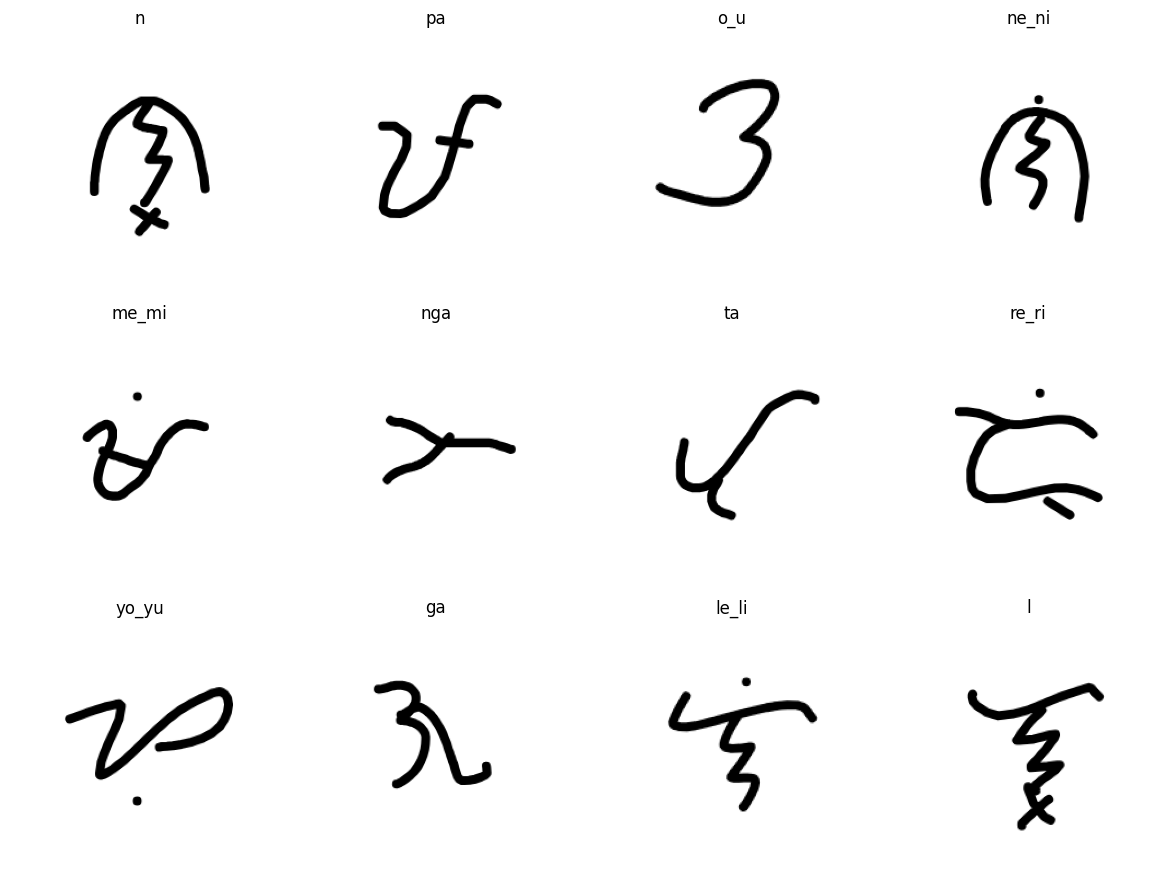

In [ ]:
sample_rows = df.sample(min(12, len(df)), random_state=SEED).reset_index(drop=True)

plt.figure(figsize=(12, 9))

for i, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGBA")

    # Composite transparent images onto white.
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)
    gray = bg.convert("L")

    plt.subplot(3, 4, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(str(row["label"]))
    plt.axis("off")

plt.tight_layout()
plt.show()


## Step 8 — Create the label mapping


In [ ]:
classes = sorted(df["label"].astype(str).unique())
label_to_id = {label: idx for idx, label in enumerate(classes)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

df["label_id"] = df["label"].astype(str).map(label_to_id).astype("int32")

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print("First 20 mappings:")
for label in classes[:20]:
    print(f"{label:12s} -> {label_to_id[label]}")

if NUM_CLASSES != 63:
    print(f"\nNOTE: Current combined dataset has {NUM_CLASSES} classes instead of 63.")


Number of classes: 63
First 20 mappings:
a            -> 0
b            -> 1
ba           -> 2
be_bi        -> 3
bo_bu        -> 4
d            -> 5
da_ra        -> 6
de_di        -> 7
do_du        -> 8
e_i          -> 9
g            -> 10
ga           -> 11
ge_gi        -> 12
go_gu        -> 13
h            -> 14
ha           -> 15
he_hi        -> 16
ho_hu        -> 17
k            -> 18
ka           -> 19


In [ ]:
# ============================================================
# BAYA STRICT DATASET AUDIT
# Verify all 63 classes and exact number of samples per class
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# Canonical 63 BAYA classes
# ------------------------------------------------------------

VOWELS = [
    "a",
    "e_i",
    "o_u",
]

BASE_CONSONANTS = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

A_FORMS = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

EI_FORMS = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

OU_FORMS = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]

EXPECTED_LABELS = (
    VOWELS
    + BASE_CONSONANTS
    + A_FORMS
    + EI_FORMS
    + OU_FORMS
)

EXPECTED_LABEL_SET = set(EXPECTED_LABELS)

EXPECTED_EXPORTS = 14
EXPECTED_SAMPLES_PER_EXPORT = 315
EXPECTED_CLASSES = 63

# 315 / 63 = 5
EXPECTED_PER_CLASS_PER_EXPORT = (
    EXPECTED_SAMPLES_PER_EXPORT // EXPECTED_CLASSES
)

# 14 * 5 = 70
EXPECTED_PER_CLASS_TOTAL = (
    EXPECTED_EXPORTS * EXPECTED_PER_CLASS_PER_EXPORT
)


print("=" * 70)
print("BAYA STRICT DATASET AUDIT")
print("=" * 70)

print("Expected classes:", EXPECTED_CLASSES)
print("Expected exports:", EXPECTED_EXPORTS)
print(
    "Expected samples/class/export:",
    EXPECTED_PER_CLASS_PER_EXPORT
)
print(
    "Expected total/class:",
    EXPECTED_PER_CLASS_TOTAL
)
print()


# ============================================================
# 1. LABEL SET CHECK
# ============================================================

actual_labels = set(df["label"].astype(str))

missing_classes = sorted(
    EXPECTED_LABEL_SET - actual_labels
)

unexpected_classes = sorted(
    actual_labels - EXPECTED_LABEL_SET
)

print("----- CLASS SET CHECK -----")
print("Actual unique classes:", len(actual_labels))
print("Missing classes:", missing_classes)
print("Unexpected classes:", unexpected_classes)

if (
    len(actual_labels) == EXPECTED_CLASSES
    and not missing_classes
    and not unexpected_classes
):
    print("✓ Exact 63-class label set confirmed.")
else:
    print("✗ CLASS SET PROBLEM FOUND.")


# ============================================================
# 2. OVERALL COUNTS PER CLASS
# ============================================================

overall_counts = (
    df["label"]
    .astype(str)
    .value_counts()
    .reindex(sorted(EXPECTED_LABELS), fill_value=0)
)

overall_audit = pd.DataFrame({
    "class": overall_counts.index,
    "actual_total": overall_counts.values,
})

overall_audit["expected_total"] = EXPECTED_PER_CLASS_TOTAL

overall_audit["difference"] = (
    overall_audit["actual_total"]
    - overall_audit["expected_total"]
)

overall_audit["status"] = np.where(
    overall_audit["actual_total"]
    == overall_audit["expected_total"],
    "OK",
    "CHECK"
)

print("\n----- OVERALL SAMPLES PER CLASS -----")
display(overall_audit)


bad_overall = overall_audit[
    overall_audit["status"] != "OK"
]

if bad_overall.empty:
    print(
        f"✓ Every class contains exactly "
        f"{EXPECTED_PER_CLASS_TOTAL} raw samples."
    )
else:
    print("✗ Unequal class counts found:")
    display(bad_overall)


# ============================================================
# 3. COUNTS PER EXPORT PER CLASS
# ============================================================

per_export = pd.crosstab(
    df["source_export"],
    df["label"].astype(str),
)

# Ensure all expected labels appear as columns
per_export = per_export.reindex(
    columns=sorted(EXPECTED_LABELS),
    fill_value=0
)

print("\n----- SAMPLES PER CLASS PER EXPORT -----")
display(per_export)


bad_positions = []

for export_name in per_export.index:
    for class_name in per_export.columns:

        count = int(
            per_export.loc[
                export_name,
                class_name
            ]
        )

        if count != EXPECTED_PER_CLASS_PER_EXPORT:
            bad_positions.append({
                "source_export": export_name,
                "class": class_name,
                "actual": count,
                "expected": EXPECTED_PER_CLASS_PER_EXPORT,
            })


if len(bad_positions) == 0:
    print(
        "\n✓ Every export contains exactly "
        f"{EXPECTED_PER_CLASS_PER_EXPORT} samples "
        "for every one of the 63 classes."
    )
else:
    print(
        "\n✗ Some exports/classes have incorrect counts:"
    )

    display(
        pd.DataFrame(bad_positions)
    )


# ============================================================
# 4. EXPORT TOTAL CHECK
# ============================================================

export_totals = (
    df.groupby("source_export")
    .size()
    .rename("actual_samples")
    .to_frame()
)

export_totals["expected_samples"] = (
    EXPECTED_SAMPLES_PER_EXPORT
)

export_totals["status"] = np.where(
    export_totals["actual_samples"]
    == EXPECTED_SAMPLES_PER_EXPORT,
    "OK",
    "CHECK"
)

print("\n----- EXPORT TOTALS -----")
display(export_totals)


# ============================================================
# 5. FINAL AUDIT RESULT
# ============================================================

dataset_structure_pass = (
    len(actual_labels) == EXPECTED_CLASSES
    and len(missing_classes) == 0
    and len(unexpected_classes) == 0
    and bad_overall.empty
    and len(bad_positions) == 0
    and (export_totals["status"] == "OK").all()
)

print("\n" + "=" * 70)

if dataset_structure_pass:
    print("✓ DATASET STRUCTURE AUDIT: PASS")
    print(
        "63 classes × 70 samples/class = "
        f"{63 * 70} samples"
    )
    print(
        "Every export also has "
        "5 samples per class."
    )
else:
    print("✗ DATASET STRUCTURE AUDIT: FAIL")
    print(
        "Do NOT retrain until the reported problems "
        "are investigated."
    )

print("=" * 70)

BAYA STRICT DATASET AUDIT
Expected classes: 63
Expected exports: 14
Expected samples/class/export: 5
Expected total/class: 70

----- CLASS SET CHECK -----
Actual unique classes: 63
Missing classes: []
Unexpected classes: []
✓ Exact 63-class label set confirmed.

----- OVERALL SAMPLES PER CLASS -----


,class,actual_total,expected_total,difference,status
0,a,70,70,0,OK
1,b,70,70,0,OK
2,ba,70,70,0,OK
3,be_bi,70,70,0,OK
4,bo_bu,70,70,0,OK
...,...,...,...,...,...
58,wo_wu,70,70,0,OK
59,y,70,70,0,OK
60,ya,70,70,0,OK
61,ye_yi,70,70,0,OK


✓ Every class contains exactly 70 raw samples.

----- SAMPLES PER CLASS PER EXPORT -----


label,a,b,ba,be_bi,bo_bu,d,da_ra,de_di,do_du,e_i,...,te_ti,to_tu,w,wa,we_wi,wo_wu,y,ya,ye_yi,yo_yu
source_export,,,,,,,,,,,,,,,,,,,,,
BAYA_dataset_2026-09-12T03-51-35-334Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-12T05-43-06-183Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-12T06-40-53-944Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-12T07-47-28-468Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-12T08-33-47-340Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-13T04-12-06-104Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-13T08-10-00-545Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-13T09-02-49-162Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
BAYA_dataset_2026-09-13T10-34-50-057Z,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5



✓ Every export contains exactly 5 samples for every one of the 63 classes.

----- EXPORT TOTALS -----


,actual_samples,expected_samples,status
source_export,,,
BAYA_dataset_2026-09-12T03-51-35-334Z,315,315,OK
BAYA_dataset_2026-09-12T05-43-06-183Z,315,315,OK
BAYA_dataset_2026-09-12T06-40-53-944Z,315,315,OK
BAYA_dataset_2026-09-12T07-47-28-468Z,315,315,OK
BAYA_dataset_2026-09-12T08-33-47-340Z,315,315,OK
BAYA_dataset_2026-09-13T04-12-06-104Z,315,315,OK
BAYA_dataset_2026-09-13T08-10-00-545Z,315,315,OK
BAYA_dataset_2026-09-13T09-02-49-162Z,315,315,OK
BAYA_dataset_2026-09-13T10-34-50-057Z,315,315,OK



✓ DATASET STRUCTURE AUDIT: PASS
63 classes × 70 samples/class = 4410 samples
Every export also has 5 samples per class.


## Step 9 — Define position and size-normalized image preprocessing

1. finds the handwriting bounding box;
2. crops around all visible handwriting, including kudlit marks;
3. adds proportional padding;
4. centers the crop on a square background;
5. preserves the character's aspect ratio;
6. resizes the standardized square to **96 × 96**.


Image tensor shape: (96, 96, 1)
Pixel range: 0.0 to 1.0


/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


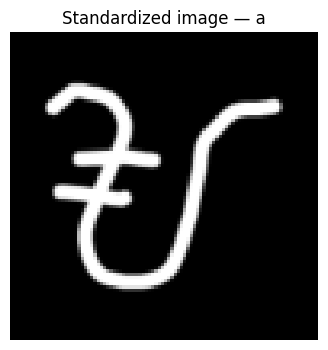

In [ ]:
IMAGE_PADDING_RATIO = 0.15
INK_THRESHOLD = 0.08


def load_image_array(image_path):
    # 1. Load and place transparent images on white.
    img = Image.open(image_path).convert("RGBA")
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)

    # 2. Convert to grayscale.
    gray = bg.convert("L")
    arr = np.asarray(gray, dtype=np.float32) / 255.0

    # 3. Convert black handwriting to high-valued ink.
    #    white background -> 0
    #    black handwriting -> 1
    ink = 1.0 - arr

    # 4. Detect all visible handwriting.
    mask = ink > INK_THRESHOLD

    if np.any(mask):
        ys, xs = np.where(mask)

        y0, y1 = int(ys.min()), int(ys.max()) + 1
        x0, x1 = int(xs.min()), int(xs.max()) + 1

        # 5. Crop to the handwriting bounding box.
        crop = ink[y0:y1, x0:x1]

        crop_h, crop_w = crop.shape
        max_dim = max(crop_h, crop_w)

        # 6. Add proportional padding around the character.
        padding = max(2, int(round(max_dim * IMAGE_PADDING_RATIO)))
        square_side = max_dim + 2 * padding

        # 7. Center on a square canvas while preserving aspect ratio.
        square = np.zeros((square_side, square_side), dtype=np.float32)

        top = (square_side - crop_h) // 2
        left = (square_side - crop_w) // 2

        square[top:top + crop_h, left:left + crop_w] = crop
    else:
        # Fallback for an unexpectedly blank image.
        square = ink

    # 8. Resize only after centering / scale normalization.
    square_u8 = np.clip(square * 255.0, 0, 255).astype(np.uint8)
    standardized = Image.fromarray(square_u8, mode="L").resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR,
    )

    result = np.asarray(standardized, dtype=np.float32) / 255.0

    # H x W x 1
    result = np.expand_dims(result, axis=-1)
    return result.astype(np.float32)


# Quick preprocessing check
test_img = load_image_array(df.iloc[0]["image_path"])

print("Image tensor shape:", test_img.shape)
print("Pixel range:", float(test_img.min()), "to", float(test_img.max()))

plt.figure(figsize=(4, 4))
plt.imshow(test_img[..., 0], cmap="gray")
plt.title(f"Standardized image — {df.iloc[0]['label']}")
plt.axis("off")
plt.show()


## Step 10 — Split by complete source export: 10 / 2 / 2

Because your current `BAYA_DATASETS.zip` contains **14 complete exports**, this notebook uses:

```
10 exports → Training
 2 exports → Validation
 2 exports → Testing
```

If every export contains 315 attempts, this gives:

```
Training:   3,150 samples
Validation:   630 samples
Testing:      630 samples
```

The split is performed by **whole export**, never by random individual PNG.

This helps prevent repeated attempts from the same collection session from being divided between training and testing.

> Important: `source_export` is a collection-session identifier, not necessarily a person identifier. If the same participant produced multiple ZIP exports, those exports should later be grouped under the same participant before the final thesis evaluation.


In [ ]:
groups = sorted(df["source_export"].unique())

if len(groups) < 3:
    raise ValueError(
        f"Need at least 3 source exports for group splitting; found {len(groups)}."
    )

rng = np.random.default_rng(SEED)
shuffled_groups = np.array(groups, dtype=object)
rng.shuffle(shuffled_groups)

# For the current 14-export dataset: exactly 10 train / 2 val / 2 test.
if len(groups) == 14:
    n_test = 2
    n_val = 2
else:
    # General fallback if the dataset changes later.
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))

    while n_test + n_val >= len(groups):
        if n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            break

test_groups = list(shuffled_groups[:n_test])
val_groups = list(shuffled_groups[n_test:n_test + n_val])
train_groups = list(shuffled_groups[n_test + n_val:])

train_df = df[df["source_export"].isin(train_groups)].reset_index(drop=True)
val_df = df[df["source_export"].isin(val_groups)].reset_index(drop=True)
test_df = df[df["source_export"].isin(test_groups)].reset_index(drop=True)

print("========== GROUP SPLIT ==========")
print(f"TRAIN ({len(train_groups)} exports)")
for g in train_groups:
    print(" -", g)

print(f"\nVALIDATION ({len(val_groups)} exports)")
for g in val_groups:
    print(" -", g)

print(f"\nTEST ({len(test_groups)} exports)")
for g in test_groups:
    print(" -", g)

print("\nSample counts")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Verify there is no source-export leakage.
assert set(train_groups).isdisjoint(val_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(val_groups).isdisjoint(test_groups)

# Check that every split contains all labels.
for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing = sorted(set(classes) - set(part["label"].astype(str)))
    print(
        f"{name}: exports={part['source_export'].nunique()}, "
        f"samples={len(part)}, "
        f"classes={part['label'].nunique()}, "
        f"missing={len(missing)}"
    )
    if missing:
        print(" Missing labels:", missing[:20])
if set(classes) - set(train_df["label"].astype(str)):
    raise ValueError("Training exports do not contain all classes. Review the group split.")


if REFERENCE_PREPROCESS_PATH is not None:
    with open(REFERENCE_PREPROCESS_PATH, encoding="utf-8") as f:
        reference_split = json.load(f)["group_split"]
    for key, current in [("train_exports", train_groups),
                         ("validation_exports", val_groups),
                         ("test_exports", test_groups)]:
        if sorted(reference_split[key]) != sorted(current):
            raise ValueError(f"Split differs from reference: {key}. Check data and SEED.")
    print("Export split matches the reference experiment.")

split_manifest = pd.concat([
    part[["source_export", "attempt_id", "label", "image_path"]].assign(split=name)
    for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]
], ignore_index=True)
split_manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)


========== GROUP SPLIT ==========
TRAIN (10 exports)
 - BAYA_dataset_2026-09-12T03-51-35-334Z
 - BAYA_dataset_2026-09-16T10-03-56-331Z
 - BAYA_dataset_2026-09-16T15-13-05-394Z
 - BAYA_dataset_2026-09-16T09-54-32-545Z
 - BAYA_dataset_2026-09-13T04-12-06-104Z
 - BAYA_dataset_2026-09-12T06-40-53-944Z
 - BAYA_dataset_2026-09-12T08-33-47-340Z
 - BAYA_dataset_2026-09-16T11-55-03-985Z
 - BAYA_dataset_2026-09-12T05-43-06-183Z
 - BAYA_dataset_2026-09-13T10-34-50-057Z

VALIDATION (2 exports)
 - BAYA_dataset_2026-09-16T09-50-54-498Z
 - BAYA_dataset_2026-09-12T07-47-28-468Z

TEST (2 exports)
 - BAYA_dataset_2026-09-13T08-10-00-545Z
 - BAYA_dataset_2026-09-13T09-02-49-162Z

Sample counts
Train: 3150
Validation: 630
Test: 630
Total: 4410
train: exports=10, samples=3150, classes=63, missing=0
validation: exports=2, samples=630, classes=63, missing=0
test: exports=2, samples=630, classes=63, missing=0


## Step 11 — Convert each split into image tensors

- `Ximg_*`: float32 arrays with shape `(N, 96, 96, 1)`
- `y_*`: integer class IDs

White background maps to zero; dark ink maps to values near one. All original
arrays remain unaugmented. Augmentation is applied to training batches only.


In [ ]:
def dataframe_to_arrays(part_df, name="dataset"):
    if part_df.empty:
        raise ValueError(f"The {name} split is empty.")
    images, labels = [], []
    for i, row in part_df.iterrows():
        image = load_image_array(row["image_path"])
        if not np.isfinite(image).all():
            raise ValueError(f"Non-finite image values: {row['image_path']}")
        if not np.any(image > INK_THRESHOLD):
            raise ValueError(f"Image contains no detectable ink: {row['image_path']}")
        images.append(image)
        labels.append(int(row["label_id"]))
        if (i + 1) % 250 == 0:
            print(f"{name}: processed {i + 1}/{len(part_df)}")
    return np.stack(images).astype(np.float32), np.asarray(labels, dtype=np.int32)

Ximg_train, y_train = dataframe_to_arrays(train_df, "train")
Ximg_val, y_val = dataframe_to_arrays(val_df, "validation")
Ximg_test, y_test = dataframe_to_arrays(test_df, "test")
for name, images, labels in [
    ("Train", Ximg_train, y_train),
    ("Validation", Ximg_val, y_val),
    ("Test", Ximg_test, y_test),
]:
    print(name, "images:", images.shape, "labels:", labels.shape)


/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


train: processed 250/3150
train: processed 500/3150
train: processed 750/3150
train: processed 1000/3150
train: processed 1250/3150
train: processed 1500/3150
train: processed 1750/3150
train: processed 2000/3150
train: processed 2250/3150
train: processed 2500/3150
train: processed 2750/3150
train: processed 3000/3150
validation: processed 250/630
validation: processed 500/630
test: processed 250/630
test: processed 500/630
Train images: (3150, 96, 96, 1) labels: (3150,)
Validation images: (630, 96, 96, 1) labels: (630,)
Test images: (630, 96, 96, 1) labels: (630,)


## Training-only image augmentation

### Training-only handwriting augmentation

Small random rotations (up to ±8°), scale changes (0.90–1.10×), and translations (up to 3% of the canvas) are applied on the fly to 80% of training images. These conservative changes approximate writing variation while retaining orientation and kudlit marks. There are no flips, crops, erasing, or mark removal. A bounds check includes all nonzero ink, including faint pixels and an interpolation margin; if no sampled transform fits, the image is retained unchanged. Bilinear resampling can slightly soften small marks, so compare validation results with `AUGMENTATION_ENABLED = False` when tuning.

The generator preserves source images and labels, shuffles training samples deterministically, and creates reproducible transforms from the seed, epoch, and original sample index. Validation and test images remain unchanged. The image-only CNN accepts its returned image batches directly. Set `shuffle=False` in `model.fit`, because the generator already manages sample order. Keep configuration constants unchanged during a training run.


In [ ]:
# Training-only, label-preserving augmentation of standardized handwriting.
# Keep geometric changes small: kudlit marks and orientation distinguish classes.
# Augmentation settings are defined once in the experiment configuration cell.


def augment_handwriting_image(image, rng):
    """Transform a copy; keep all ink on the canvas and fall back if needed."""
    result = np.asarray(image, dtype=np.float32).copy()
    if result.ndim != 3 or result.shape[-1] != 1:
        raise ValueError("Expected a grayscale image with shape (height, width, 1).")
    if not np.isfinite(result).all():
        raise ValueError("Augmentation received non-finite image values.")
    if not AUGMENTATION_ENABLED or rng.random() >= AUG_PROBABILITY:
        return result

    height, width = result.shape[:2]
    ys, xs = np.nonzero(result[..., 0] > 0.0)
    if not len(xs):
        return result

    # Include faint ink and an extra interpolation margin around its bounding box.
    # Coordinates use the whole normalized canvas, with center (0.5, 0.5).
    lower = np.array([(xs.min() - 1) / width, (ys.min() - 1) / height])
    upper = np.array([(xs.max() + 2) / width, (ys.max() + 2) / height])
    corners = np.array([
        [lower[0], lower[1]], [upper[0], lower[1]],
        [lower[0], upper[1]], [upper[0], upper[1]],
    ], dtype=np.float64)
    center = np.array([0.5, 0.5])
    pixels = np.diag([float(width), float(height)])

    for _ in range(12):
        angle = np.deg2rad(rng.uniform(-AUG_ROTATION_DEGREES, AUG_ROTATION_DEGREES))
        scale = rng.uniform(*AUG_SCALE_RANGE)
        rotation = np.array([[np.cos(angle), -np.sin(angle)],
                             [np.sin(angle), np.cos(angle)]])
        linear = scale * rotation
        moved = (corners - center) @ linear.T + center
        # Sample only translations that keep the complete ink bounds in-frame.
        low = np.maximum(-AUG_TRANSLATION_FRACTION, -moved.min(axis=0))
        high = np.minimum(AUG_TRANSLATION_FRACTION, 1.0 - moved.max(axis=0))
        if np.any(low > high):
            continue
        translation = rng.uniform(low, high)
        offset = center - linear @ center + translation
        forward = pixels @ linear @ np.linalg.inv(pixels)
        forward_offset = pixels @ offset
        inverse = np.linalg.inv(forward)
        inverse_offset = -inverse @ forward_offset
        coefficients = (
            inverse[0, 0], inverse[0, 1], inverse_offset[0],
            inverse[1, 0], inverse[1, 1], inverse_offset[1],
        )
        warped = Image.fromarray(result[..., 0]).transform(
            (width, height), Image.Transform.AFFINE, coefficients,
            resample=Image.Resampling.BILINEAR, fillcolor=0.0,
        )
        transformed = np.asarray(warped, dtype=np.float32)
        return np.clip(transformed, 0.0, 1.0)[..., np.newaxis]

    # Unusual edge-filling inputs can leave no safe transform within these ranges.
    return result


class ImageAugmentationSequence(tf.keras.utils.Sequence):
    """Deterministic per-sample/epoch augmentation without changing source arrays."""

    def __init__(self, images, labels, batch_size=BATCH_SIZE, seed=SEED,
                 shuffle=True, **kwargs):
        # Supports Keras 3 worker/queue options when explicitly supplied.
        super().__init__(**kwargs)
        self.images = np.asarray(images)
        self.labels = np.asarray(labels)
        if len(self.images) != len(self.labels) or len(self.images) == 0:
            raise ValueError("Images and labels must have equal, nonzero lengths.")
        if self.images.ndim != 4 or self.images.shape[-1] != 1:
            raise ValueError("Expected images with shape (samples, height, width, 1).")
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.shuffle = bool(shuffle)
        if self.batch_size < 1 or self.seed < 0:
            raise ValueError("batch_size must be positive and seed nonnegative.")
        if not (0.0 <= AUG_PROBABILITY <= 1.0):
            raise ValueError("AUG_PROBABILITY must be between 0 and 1.")
        if (len(AUG_SCALE_RANGE) != 2 or not 0 < AUG_SCALE_RANGE[0] <= AUG_SCALE_RANGE[1]
                or AUG_ROTATION_DEGREES < 0 or AUG_TRANSLATION_FRACTION < 0):
            raise ValueError("Invalid augmentation ranges.")
        self._state = self._make_state(0)

    def _make_state(self, epoch):
        indices = np.arange(len(self.labels))
        if self.shuffle:
            rng = np.random.default_rng(np.random.SeedSequence([self.seed, epoch, 0]))
            rng.shuffle(indices)
        indices.setflags(write=False)
        return epoch, indices

    def __len__(self):
        return (len(self.labels) + self.batch_size - 1) // self.batch_size

    def __getitem__(self, batch_index):
        if batch_index < 0 or batch_index >= len(self):
            raise IndexError("Batch index out of range.")
        # A single immutable state snapshot keeps concurrent batch reads coherent.
        epoch, indices = self._state
        selected = indices[batch_index * self.batch_size:(batch_index + 1) * self.batch_size]
        batch_images = np.empty((len(selected),) + self.images.shape[1:], dtype=np.float32)
        for position, sample_index in enumerate(selected):
            rng = np.random.default_rng(np.random.SeedSequence([
                self.seed, epoch, 1, int(sample_index)
            ]))
            batch_images[position] = augment_handwriting_image(self.images[sample_index], rng)
        return batch_images, self.labels[selected].copy()

    def on_epoch_end(self):
        self._state = self._make_state(self._state[0] + 1)


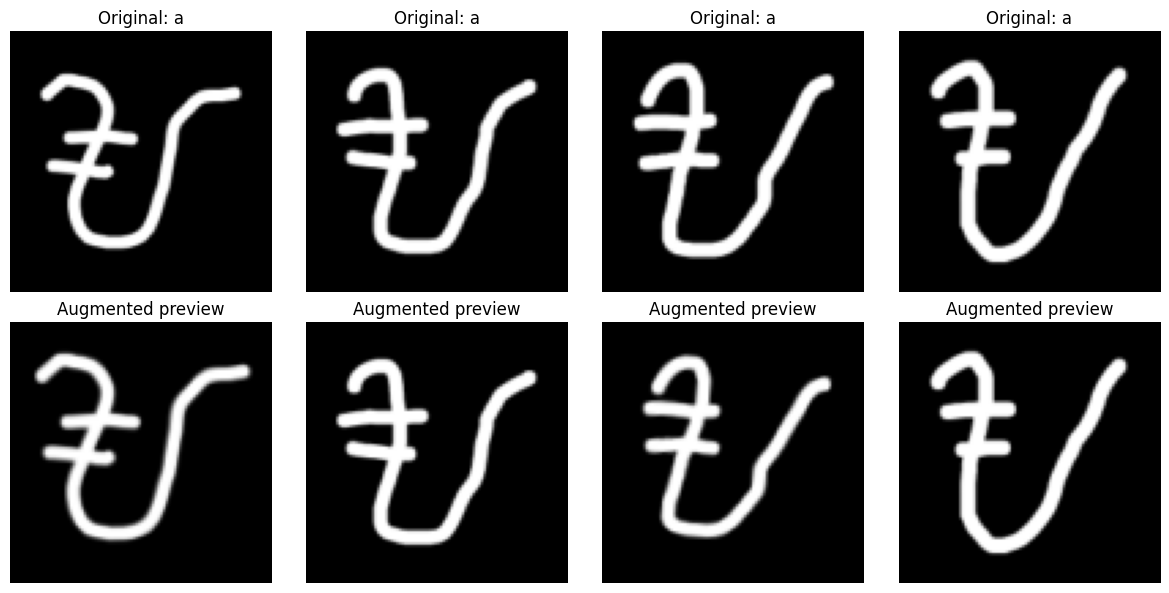

In [ ]:
# Visual preview uses a separate RNG and never modifies the training arrays.
preview_rng = np.random.default_rng(SEED)
preview_count = min(4, len(Ximg_train))
fig, axes = plt.subplots(2, preview_count, figsize=(3 * preview_count, 6), squeeze=False)
for i in range(preview_count):
    augmented = augment_handwriting_image(Ximg_train[i], preview_rng)
    axes[0, i].imshow(Ximg_train[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Original: {id_to_label[int(y_train[i])]}")
    axes[1, i].imshow(augmented[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Augmented preview")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()


## Step 12 — Build EfficientNetB0

The public input stays `(96,96,1)`, with ink=1 and background=0. Inside the model,
the channel is repeated three times, then inverted/scaled to black ink on white
RGB in [0,255]. EfficientNetB0 applies its own built-in rescaling and normalization.
No external `preprocess_input` call or double rescaling is needed.

The original ImageNet classifier is replaced by global average pooling,
Dense 128 (ReLU), Dropout 0.40, and one softmax output per dataset class.
Pretrained weights support this 96 × 96 input with `include_top=False`.


In [ ]:
def compile_classifier(classifier, learning_rate):
    classifier.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )


def build_efficientnetb0(num_classes):
    image_input = layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), name="image_input"
    )
    rgb = layers.Concatenate(axis=-1, name="grayscale_to_rgb")(
        [image_input, image_input, image_input]
    )
    rgb_255 = layers.Rescaling(-255.0, offset=255.0, name="ink_to_rgb_255")(rgb)
    backbone = tf.keras.applications.EfficientNetB0(
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
        include_top=False, weights=BACKBONE_WEIGHTS,
        pooling="avg",
    )
    if BACKBONE_WEIGHTS == "imagenet":
        backbone.trainable = False
        features = backbone(rgb_255, training=False)
    else:
        backbone.trainable = True
        features = backbone(rgb_255)
    x = layers.Dense(128, activation="relu", name="image_features")(features)
    x = layers.Dropout(0.40, name="classifier_dropout")(x)
    output = layers.Dense(num_classes, activation="softmax", name="character_output")(x)
    classifier = Model(image_input, output, name="BAYA_EfficientNetB0")
    compile_classifier(classifier, LEARNING_RATE)
    return classifier, backbone.name


model, BASE_MODEL_NAME = build_efficientnetb0(NUM_CLASSES)
model.summary()
print("Training regime:", TRAINING_REGIME)
print("Parameters:", model.count_params())


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "BAYA_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 96, 96, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grayscale_to_rgb    │ (None, 96, 96, 3) │          0 │ image_input[0][0… │
│ (Concatenate)       │                   │            │ image_input[0][0… │
│                     │                   │            │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ink_to_rgb_255      │ (None, 96, 96, 3) │          0 │ grayscale_to_rgb… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ ink_to_rgb_255[0… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 128)       │    163,968 │ efficientnetb0[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ image_features[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ character_output    │ (None, 63)        │      8,127 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,221,666 (16.10 MB)

 Trainable params: 172,095 (672.25 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Training regime: imagenet_finetuned
Parameters: 4221666


## Step 13 — Define training callbacks

ModelCheckpoint saves the best validation-loss model for each stage.
ReduceLROnPlateau lowers the learning rate after four unimproved epochs.
TerminateOnNaN stops numerically invalid training. Early stopping is disabled.
After all training, the best checkpoint across both stages is selected for test
evaluation and final export. Later worse epochs cannot replace that selection.


In [ ]:
def make_callbacks(stage_checkpoint):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            str(stage_checkpoint), monitor="val_loss", mode="min",
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=0.5,
            patience=4, min_lr=1e-6, verbose=1,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ]


## Step 14 — Train and select the best validation checkpoint

Transfer mode first trains the classification head and then fine-tunes the backbone
with a lower learning rate and frozen BatchNorm statistics. Scratch mode trains all
layers from random initialization. Both use the shared image augmentation generator.
The combined history records every executed epoch and its training stage.


In [ ]:
from types import SimpleNamespace

if EPOCHS < 1:
    raise ValueError("EPOCHS must be positive.")
if BACKBONE_WEIGHTS == "imagenet" and not (1 <= WARMUP_EPOCHS < EPOCHS):
    raise ValueError("Set 1 <= WARMUP_EPOCHS < EPOCHS for two-stage transfer learning.")

train_dataset = ImageAugmentationSequence(
    Ximg_train, y_train, batch_size=BATCH_SIZE, seed=SEED, shuffle=True
)
combined_history = {}
training_stages = []
stage_candidates = []

def fit_stage(stage_name, epoch_budget):
    stage_path = OUTPUT_DIR / f"{MODEL_NAME}_{stage_name}_{MODEL_VERSION}.keras"
    result = model.fit(
        train_dataset, validation_data=(Ximg_val, y_val), epochs=epoch_budget,
        callbacks=make_callbacks(stage_path), shuffle=False, verbose=1,
    )
    losses = np.asarray(result.history["val_loss"], dtype=float)
    if not np.isfinite(losses).all() or not stage_path.is_file():
        raise RuntimeError(f"{stage_name}: no valid checkpoint; inspect training errors.")
    offset = len(training_stages)
    best_local = int(np.argmin(losses))
    stage_candidates.append({
        "stage": stage_name, "path": stage_path,
        "val_loss": float(losses[best_local]),
        "best_epoch": offset + best_local + 1,
    })
    for key, values in result.history.items():
        combined_history.setdefault(key, []).extend(values)
    training_stages.extend([stage_name] * len(losses))

training_start = time.perf_counter()
if BACKBONE_WEIGHTS == "imagenet":
    fit_stage("warmup", WARMUP_EPOCHS)
    model = tf.keras.models.load_model(stage_candidates[-1]["path"])
    backbone = model.get_layer(BASE_MODEL_NAME)
    backbone.trainable = True
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_classifier(model, FINE_TUNE_LEARNING_RATE)
    fit_stage("finetune", EPOCHS - len(training_stages))
else:
    fit_stage("scratch", EPOCHS)
training_seconds = time.perf_counter() - training_start

selected_stage = min(stage_candidates, key=lambda entry: entry["val_loss"])
shutil.copy2(selected_stage["path"], CHECKPOINT_PATH)
history = SimpleNamespace(history=combined_history)
best_epoch = selected_stage["best_epoch"]
best_validation_loss = selected_stage["val_loss"]
best_validation_accuracy = float(combined_history["val_accuracy"][best_epoch - 1])
print(f"Best overall epoch: {best_epoch} ({selected_stage['stage']})")
print(f"Best validation loss: {best_validation_loss:.6f}")
print(f"Validation accuracy at selected epoch: {best_validation_accuracy:.4%}")
print(f"Executed epochs: {len(training_stages)}; training time: {training_seconds:.1f} s")


Epoch 1/5
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.0875 - loss: 3.8511
Epoch 1: val_loss improved from None to 2.36918, saving model to /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_warmup_1.0.keras

Epoch 1: finished saving model to /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_warmup_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 62s 335ms/step - accuracy: 0.1489 - loss: 3.4750 - val_accuracy: 0.5492 - val_loss: 2.3692 - learning_rate: 0.0010
Epoch 2/5
97/99 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3574 - loss: 2.4550
Epoch 2: val_loss improved from 2.36918 to 1.39611, saving model to /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_warmup_1.0.keras

Epoch 2: finished saving model to /content/baya_efficientnetb0_imagenet_finetuned_v1.0/Baybayin_EfficientNetB0_imagenet_finetuned_warmup_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms

## Step 15 — Plot learning curves


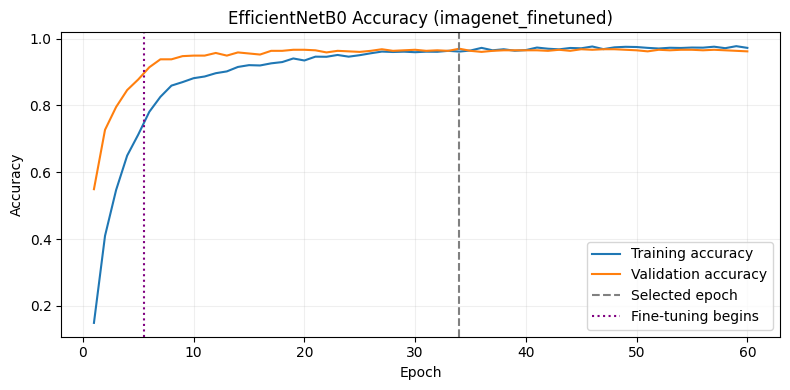

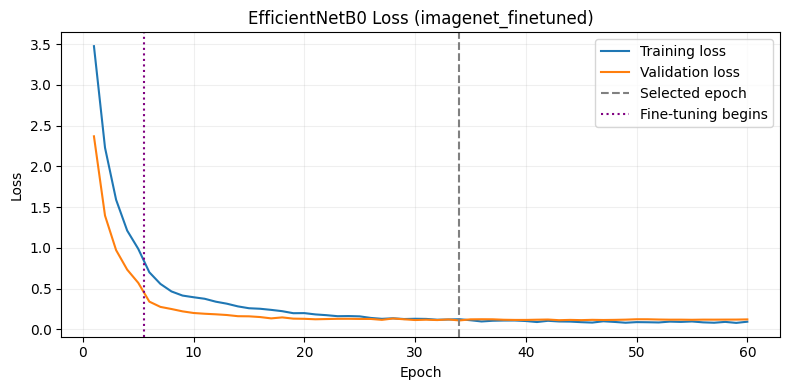

In [ ]:
epoch_axis = np.arange(1, len(history.history["loss"]) + 1)
for metric, title in [("accuracy", "Accuracy"), ("loss", "Loss")]:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epoch_axis, history.history[metric], label=f"Training {metric}")
    ax.plot(epoch_axis, history.history[f"val_{metric}"], label=f"Validation {metric}")
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Selected epoch")
    if "finetune" in training_stages:
        ax.axvline(training_stages.index("finetune") + 0.5, color="purple",
                   linestyle=":", label="Fine-tuning begins")
    ax.set(xlabel="Epoch", ylabel=title, title=f"EfficientNetB0 {title} ({TRAINING_REGIME})")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"learning_curve_{metric}.png", dpi=160)
    plt.show()


## Step 16 — Evaluate the best checkpoint on the untouched test export


In [ ]:
# Load the checkpoint selected by validation loss, then evaluate test images once.
best_model = tf.keras.models.load_model(CHECKPOINT_PATH)
test_probabilities = best_model.predict(Ximg_test, batch_size=BATCH_SIZE, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1).astype(np.int32)
accuracy = accuracy_score(y_test, y_pred)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
)

# ============================================================
# EFFICIENTNETB0 — ORGANIZED PER-CLASS TEST REPORT
# ============================================================

# Get per-class metrics
report = classification_report(
    y_test,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[id_to_label[i] for i in range(NUM_CLASSES)],
    output_dict=True,
    zero_division=0,
)

# Exact labels present in the dataset
all_labels = [id_to_label[i] for i in range(NUM_CLASSES)]


# ============================================================
# EXACT BAYA CLASS GROUPS
# 3 vowels + 15 base consonants +
# 15 A forms + 15 E/I forms + 15 O/U forms = 63 classes
# ============================================================

vowels = [
    "a",
    "e_i",
    "o_u",
]

base_consonants = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

a_forms = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

ei_forms = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

ou_forms = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]


# ============================================================
# DISPLAY LABELS
# Makes the printed report easier to read.
# Does NOT change the actual dataset/model labels.
# ============================================================

display_names = {
    # Vowels
    "a": "a",
    "e_i": "e/i",
    "o_u": "o/u",

    # Base consonants
    "b": "b",
    "d": "d",
    "g": "g",
    "h": "h",
    "k": "k",
    "l": "l",
    "m": "m",
    "n": "n",
    "ng": "ng",
    "p": "p",
    "r": "r",
    "s": "s",
    "t": "t",
    "w": "w",
    "y": "y",

    # A forms
    "ba": "ba",
    "da_ra": "da/ra",
    "ga": "ga",
    "ha": "ha",
    "ka": "ka",
    "la": "la",
    "ma": "ma",
    "na": "na",
    "nga": "nga",
    "pa": "pa",
    "ra": "ra",
    "sa": "sa",
    "ta": "ta",
    "wa": "wa",
    "ya": "ya",

    # E/I forms
    "be_bi": "be/bi",
    "de_di": "de/di",
    "ge_gi": "ge/gi",
    "he_hi": "he/hi",
    "ke_ki": "ke/ki",
    "le_li": "le/li",
    "me_mi": "me/mi",
    "ne_ni": "ne/ni",
    "nge_ngi": "nge/ngi",
    "pe_pi": "pe/pi",
    "re_ri": "re/ri",
    "se_si": "se/si",
    "te_ti": "te/ti",
    "we_wi": "we/wi",
    "ye_yi": "ye/yi",

    # O/U forms
    "bo_bu": "bo/bu",
    "do_du": "do/du",
    "go_gu": "go/gu",
    "ho_hu": "ho/hu",
    "ko_ku": "ko/ku",
    "lo_lu": "lo/lu",
    "mo_mu": "mo/mu",
    "no_nu": "no/nu",
    "ngo_ngu": "ngo/ngu",
    "po_pu": "po/pu",
    "ro_ru": "ro/ru",
    "so_su": "so/su",
    "to_tu": "to/tu",
    "wo_wu": "wo/wu",
    "yo_yu": "yo/yu",
}


# ============================================================
# PRINT GROUP FUNCTION
# ============================================================

def print_group(title, labels):

    print("\n" + "=" * 82)
    print(title)
    print("=" * 82)

    print(
        f"{'Class':<20}"
        f"{'Precision':>12}"
        f"{'Recall':>12}"
        f"{'F1-score':>12}"
        f"{'Support':>10}"
    )

    print("-" * 82)

    precisions = []
    recalls = []
    f1_scores = []
    supports = []

    for label in labels:

        if label not in report:
            print(f"WARNING: {label} not found in classification report.")
            continue

        values = report[label]

        precision = values["precision"]
        recall = values["recall"]
        f1 = values["f1-score"]
        support = int(values["support"])

        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)
        supports.append(support)

        shown_label = display_names.get(label, label)

        print(
            f"{shown_label:<20}"
            f"{precision:>12.4f}"
            f"{recall:>12.4f}"
            f"{f1:>12.4f}"
            f"{support:>10}"
        )

    if precisions:

        print("-" * 82)

        print(
            f"{'GROUP AVG':<20}"
            f"{np.mean(precisions):>12.4f}"
            f"{np.mean(recalls):>12.4f}"
            f"{np.mean(f1_scores):>12.4f}"
            f"{sum(supports):>10}"
        )


# ============================================================
# OVERALL MODEL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("EFFICIENTNETB0 — EfficientNetB0 TEST RESULTS")
print("=" * 65)

print(f"Accuracy:        {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {macro_precision:.4f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall:    {macro_recall:.4f} ({macro_recall * 100:.2f}%)")
print(f"Macro F1:        {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")


# ============================================================
# ORGANIZED CLASSIFICATION REPORT
# ============================================================

print_group(
    "1. VOWELS",
    vowels
)

print_group(
    "2. BASE CONSONANTS",
    base_consonants
)

print_group(
    "3. CONSONANTS — A FORM",
    a_forms
)

print_group(
    "4. CONSONANTS — E/I FORM",
    ei_forms
)

print_group(
    "5. CONSONANTS — O/U FORM",
    ou_forms
)


# ============================================================
# VERIFY ALL 63 CLASSES
# ============================================================

grouped_labels = (
    vowels
    + base_consonants
    + a_forms
    + ei_forms
    + ou_forms
)

missing_labels = sorted(
    set(all_labels) - set(grouped_labels)
)

extra_labels = sorted(
    set(grouped_labels) - set(all_labels)
)

duplicate_labels = sorted(
    {
        label
        for label in grouped_labels
        if grouped_labels.count(label) > 1
    }
)


print("\n" + "=" * 65)
print("GROUPING CHECK")
print("=" * 65)

print(f"Vowels:            {len(vowels)}")
print(f"Base consonants:   {len(base_consonants)}")
print(f"A forms:           {len(a_forms)}")
print(f"E/I forms:         {len(ei_forms)}")
print(f"O/U forms:         {len(ou_forms)}")
print("-" * 65)
print(f"Total grouped:     {len(grouped_labels)}")
print(f"Expected classes:  {NUM_CLASSES}")
print(f"Missing labels:    {len(missing_labels)}")
print(f"Extra labels:      {len(extra_labels)}")
print(f"Duplicates:        {len(duplicate_labels)}")


if missing_labels:
    print("\nMissing labels:")
    for label in missing_labels:
        print(" -", repr(label))

if extra_labels:
    print("\nExtra labels:")
    for label in extra_labels:
        print(" -", repr(label))

if duplicate_labels:
    print("\nDuplicate labels:")
    for label in duplicate_labels:
        print(" -", repr(label))


# ============================================================
# FINAL VALIDATION
# ============================================================

if (
    len(grouped_labels) == NUM_CLASSES
    and len(missing_labels) == 0
    and len(extra_labels) == 0
    and len(duplicate_labels) == 0
):
    print("\n✓ All 63 classes are correctly grouped exactly once.")
else:
    print("\n⚠ Check class grouping before using the report.")


20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 339ms/step

EFFICIENTNETB0 — EfficientNetB0 TEST RESULTS
Accuracy:        0.9889 (98.89%)
Macro Precision: 0.9899 (98.99%)
Macro Recall:    0.9889 (98.89%)
Macro F1:        0.9889 (98.89%)

1. VOWELS
Class                  Precision      Recall    F1-score   Support
----------------------------------------------------------------------------------
a                         1.0000      1.0000      1.0000        10
e/i                       1.0000      1.0000      1.0000        10
o/u                       1.0000      1.0000      1.0000        10
----------------------------------------------------------------------------------
GROUP AVG                 1.0000      1.0000      1.0000        30

2. BASE CONSONANTS
Class                  Precision      Recall    F1-score   Support
----------------------------------------------------------------------------------
b                         1.0000      1.0000      1.0000        10
d                         1.000

## Step 17 — Confusion matrix


✓ All grouped labels found in dataset.


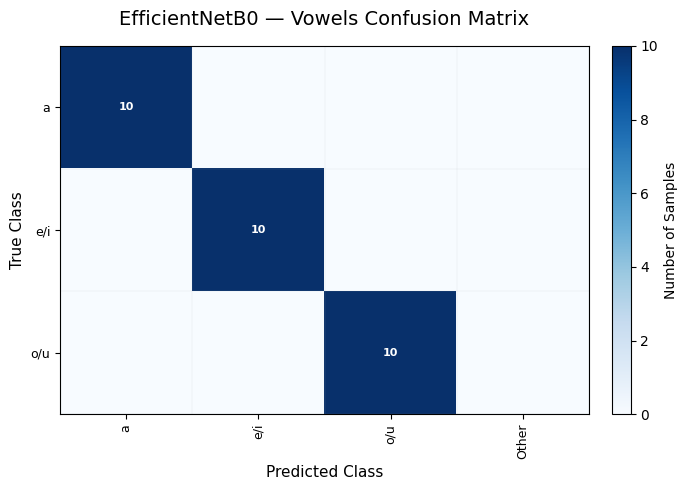


EfficientNetB0 — Vowels Confusion Matrix
Samples: 30
Correct predictions: 30
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


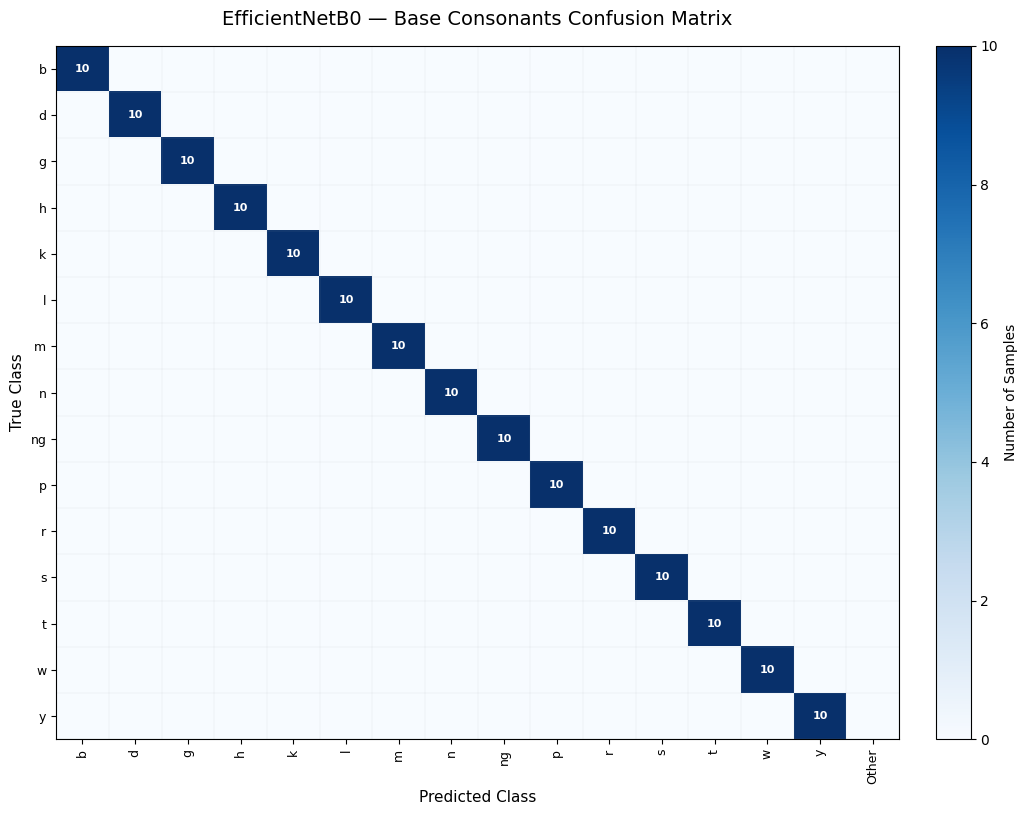


EfficientNetB0 — Base Consonants Confusion Matrix
Samples: 150
Correct predictions: 150
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


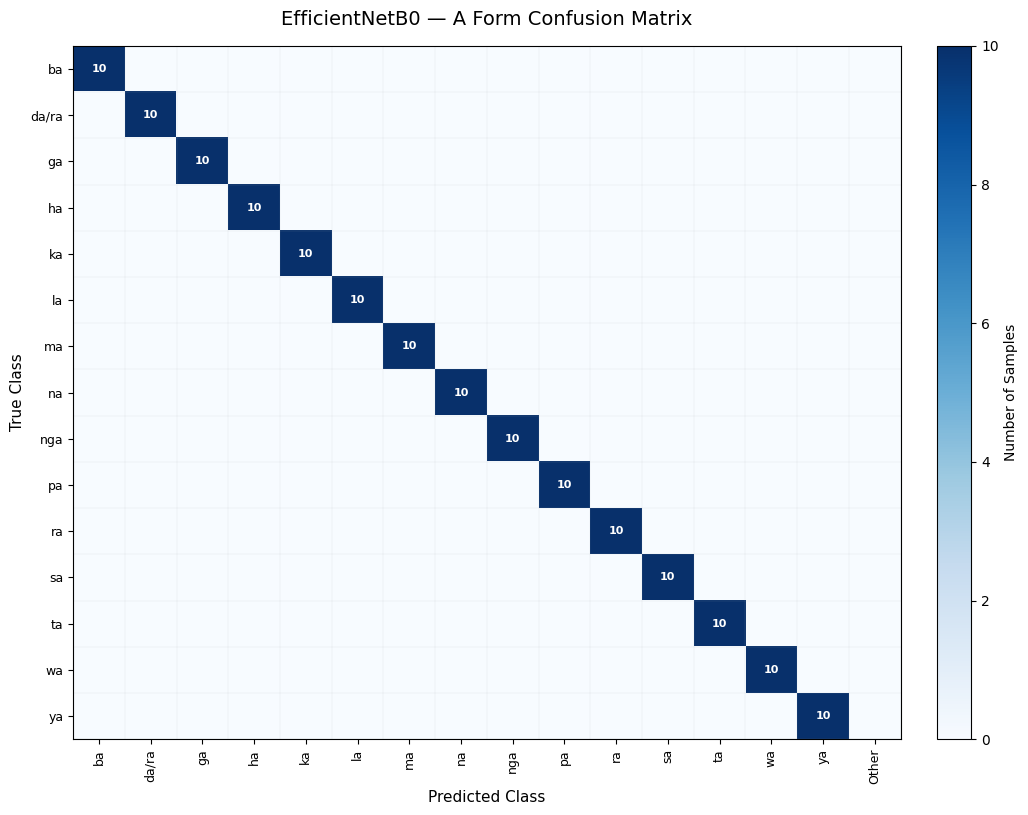


EfficientNetB0 — A Form Confusion Matrix
Samples: 150
Correct predictions: 150
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


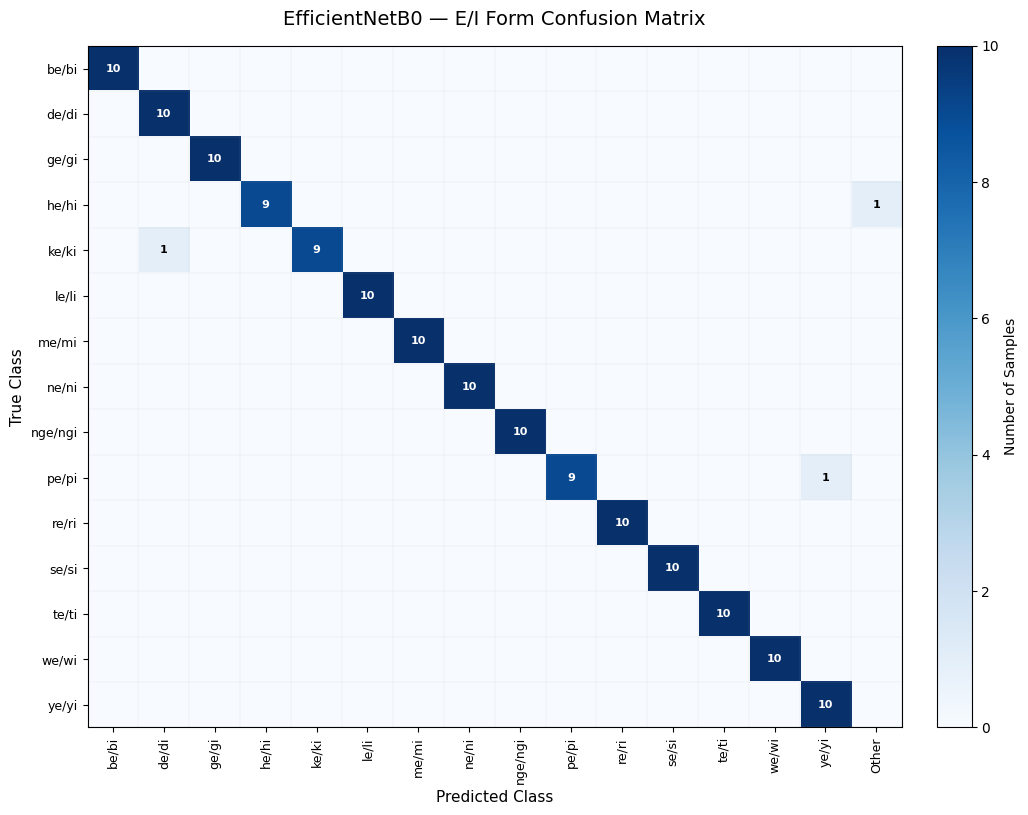


EfficientNetB0 — E/I Form Confusion Matrix
Samples: 150
Correct predictions: 147
Cross-group errors: 1
Group accuracy: 0.9800 (98.00%)
------------------------------------------------------------


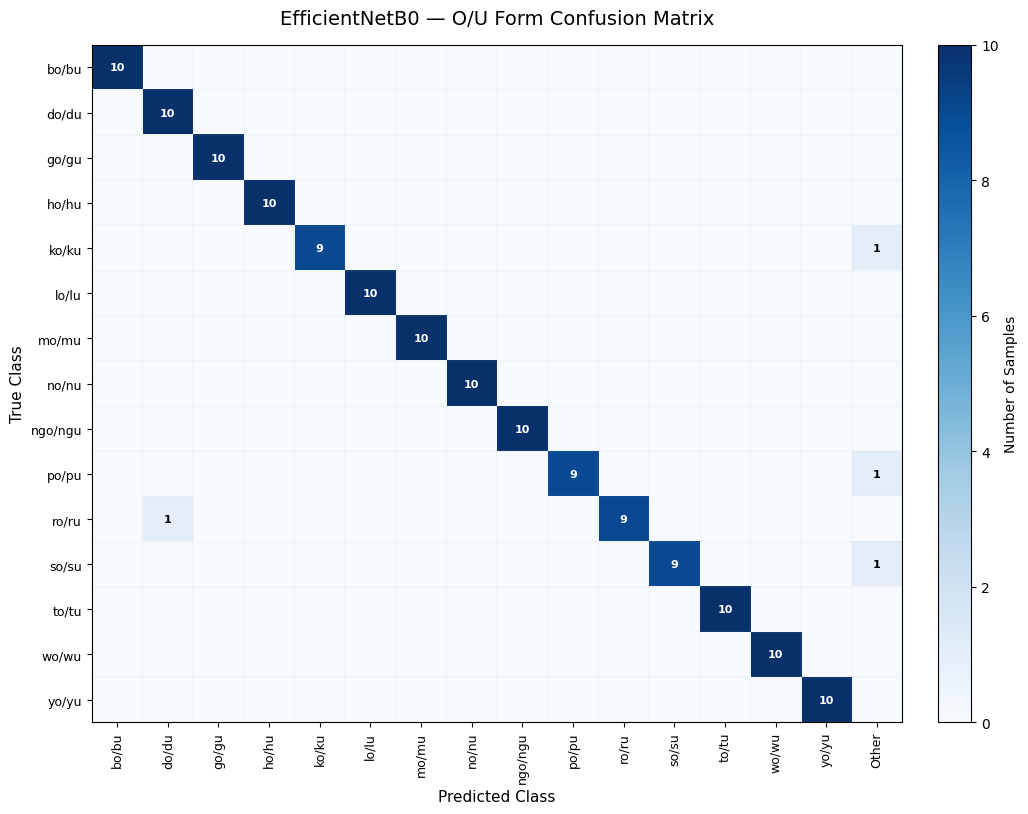


EfficientNetB0 — O/U Form Confusion Matrix
Samples: 150
Correct predictions: 146
Cross-group errors: 3
Group accuracy: 0.9733 (97.33%)
------------------------------------------------------------

EFFICIENTNETB0 — SEPARATE CONFUSION MATRICES COMPLETE
Generated matrices:
1. Vowels
2. Base Consonants
3. A Forms
4. E/I Forms
5. O/U Forms


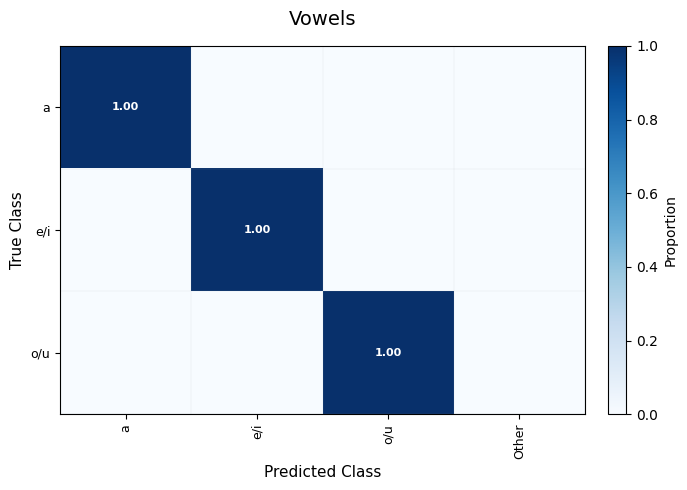


Vowels
Samples: 30
Correct predictions: 30
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


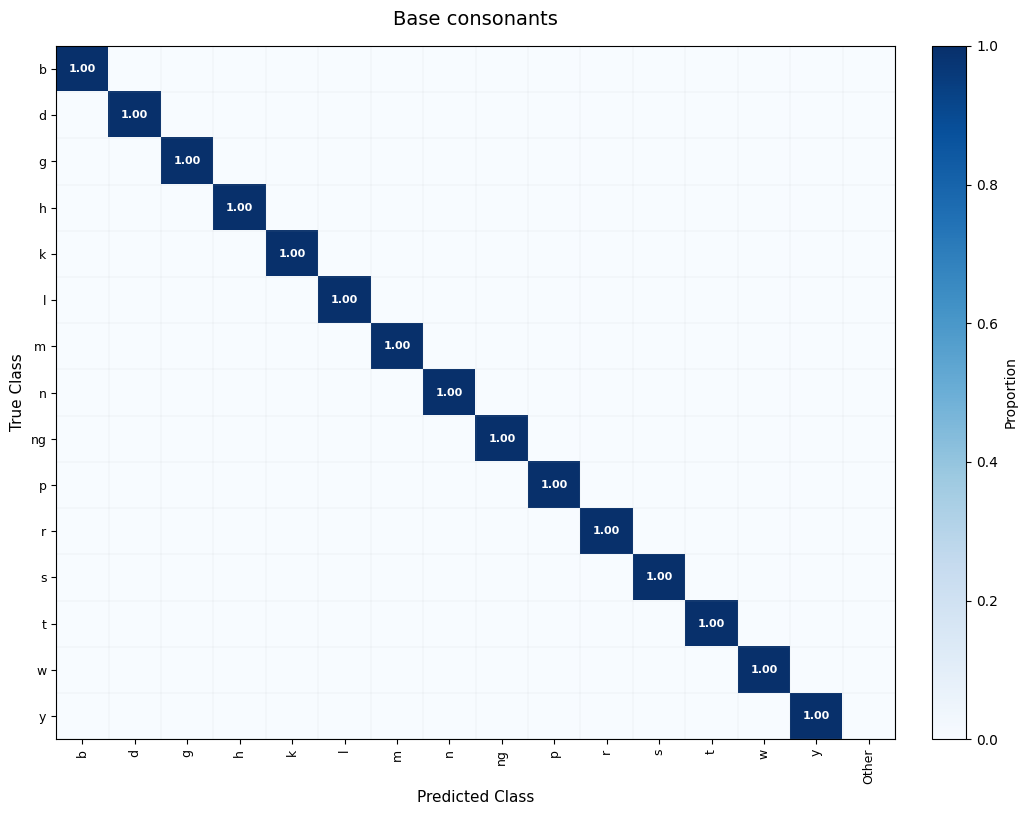


Base consonants
Samples: 150
Correct predictions: 150
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


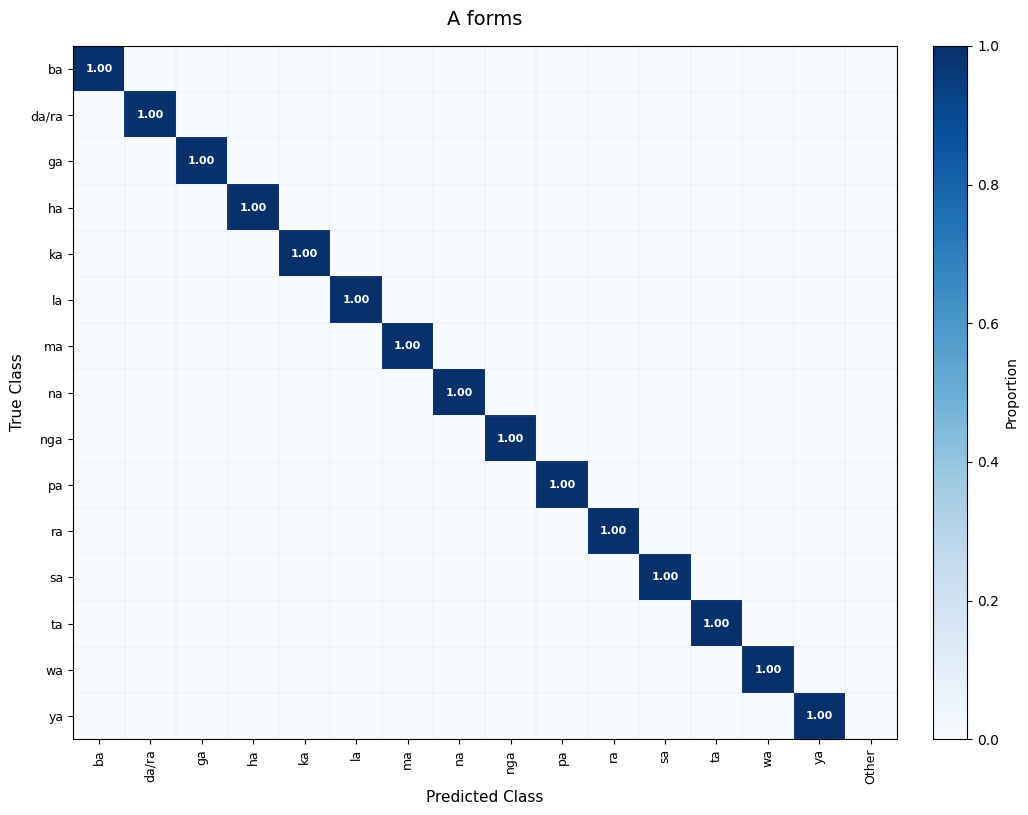


A forms
Samples: 150
Correct predictions: 150
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


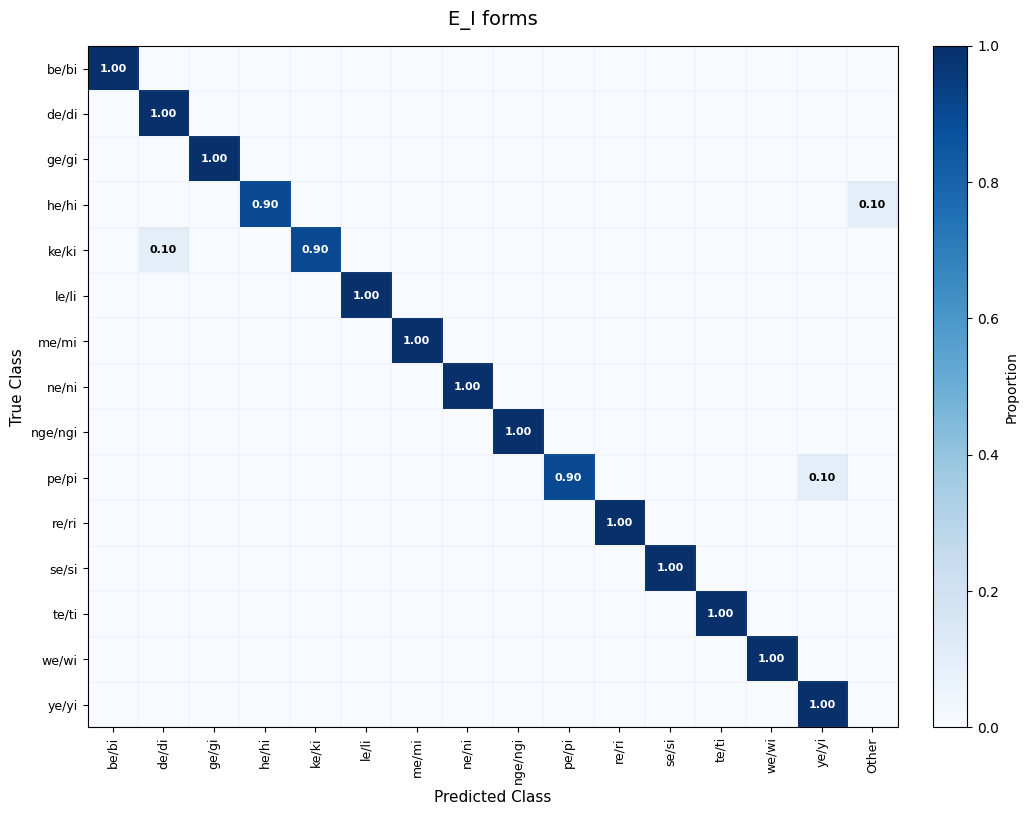


E_I forms
Samples: 150
Correct predictions: 147
Cross-group errors: 1
Group accuracy: 0.9800 (98.00%)
------------------------------------------------------------


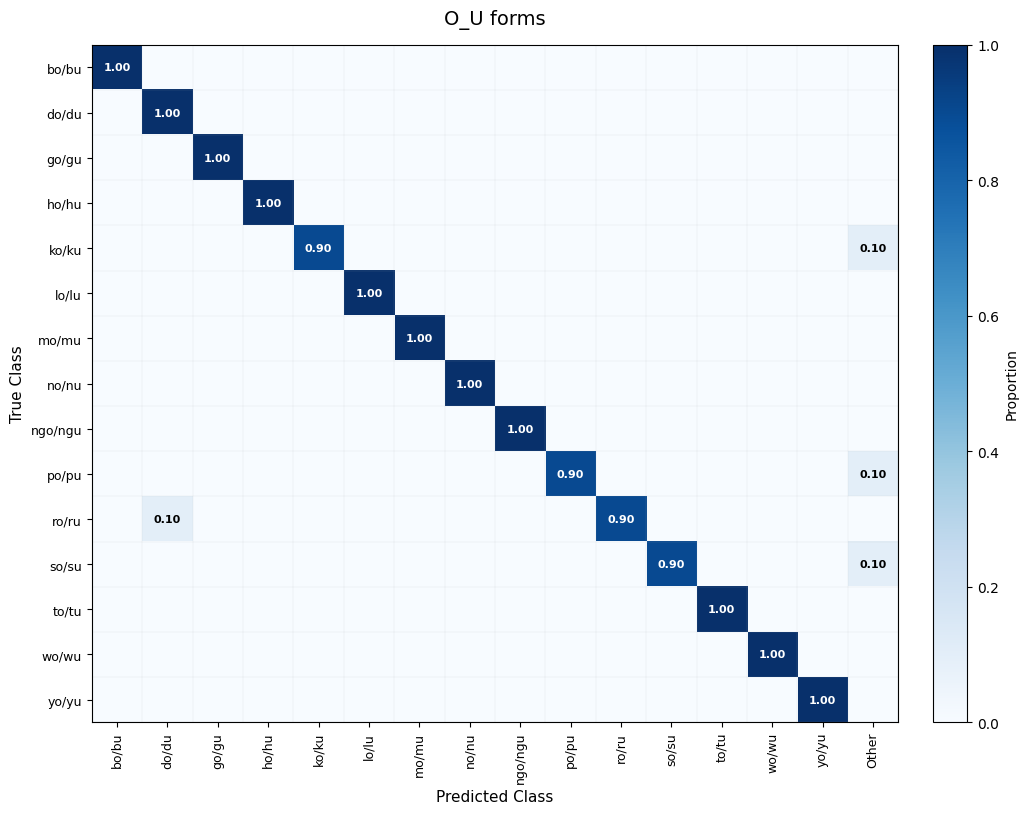


O_U forms
Samples: 150
Correct predictions: 146
Cross-group errors: 3
Group accuracy: 0.9733 (97.33%)
------------------------------------------------------------


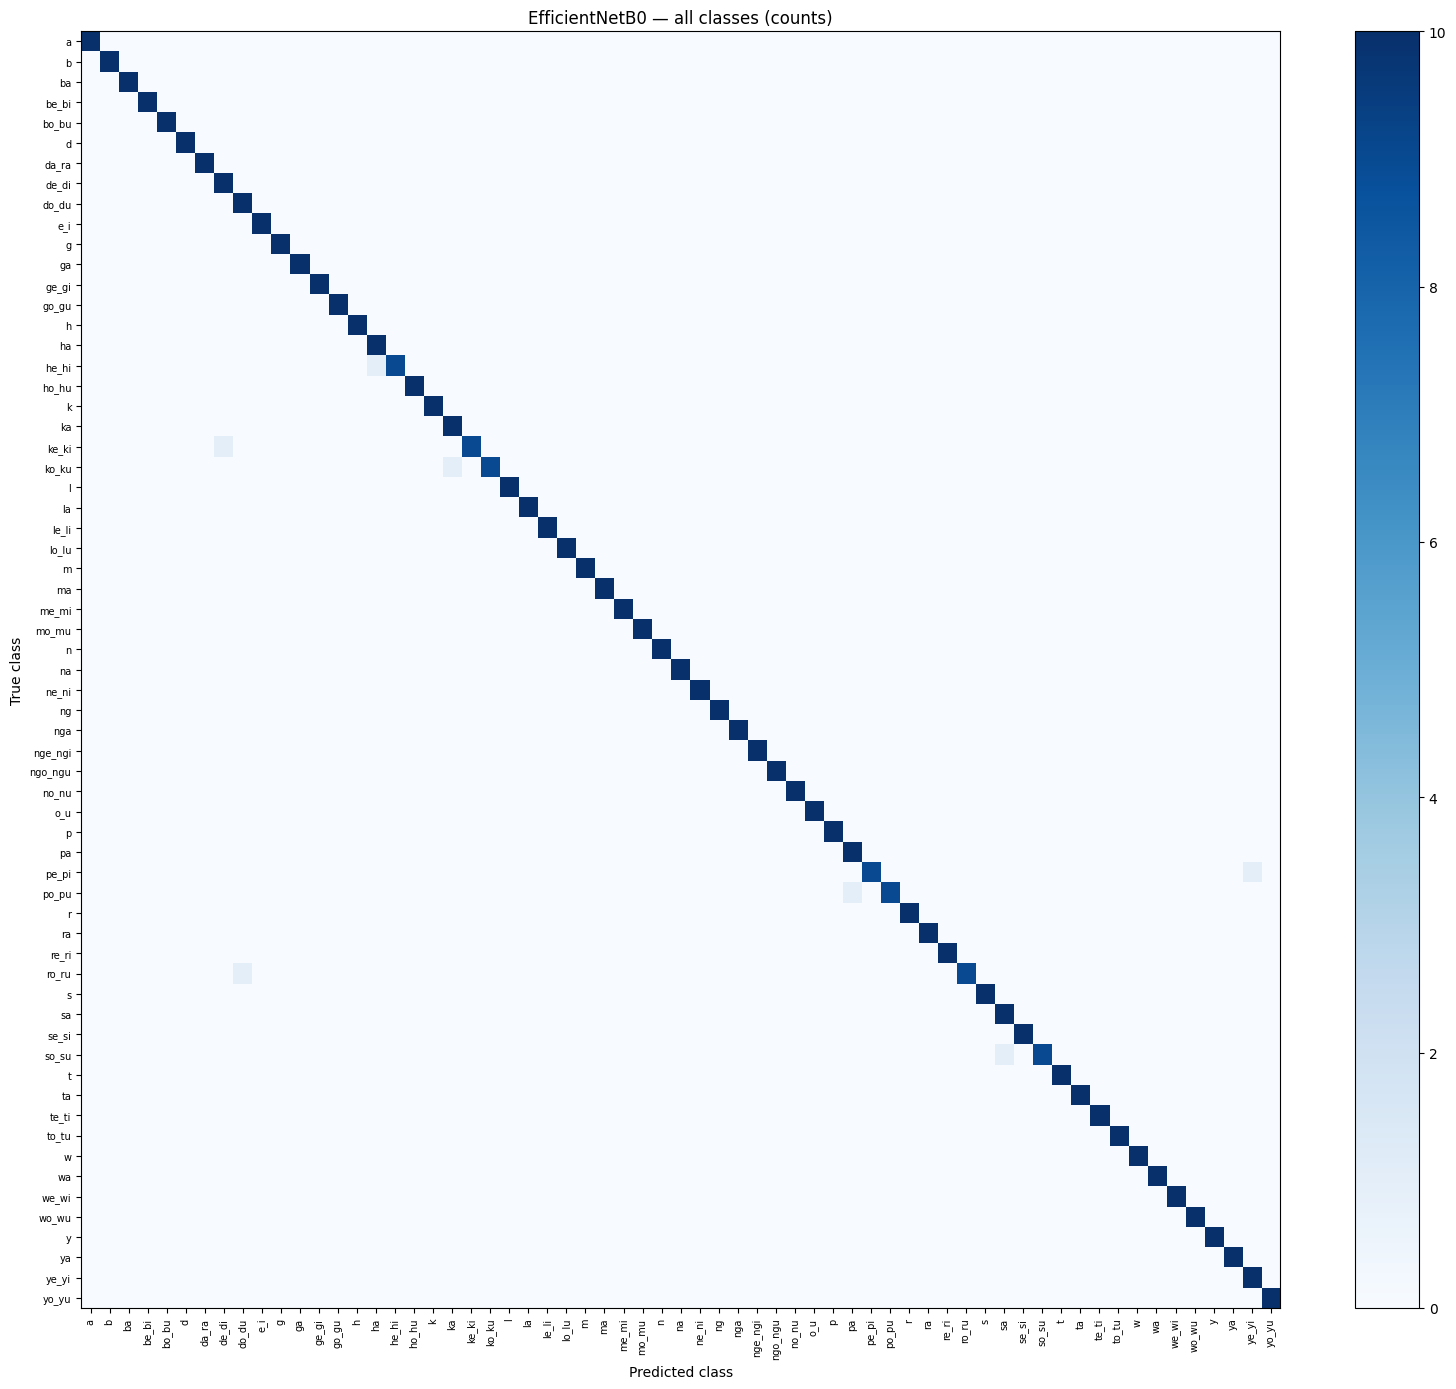

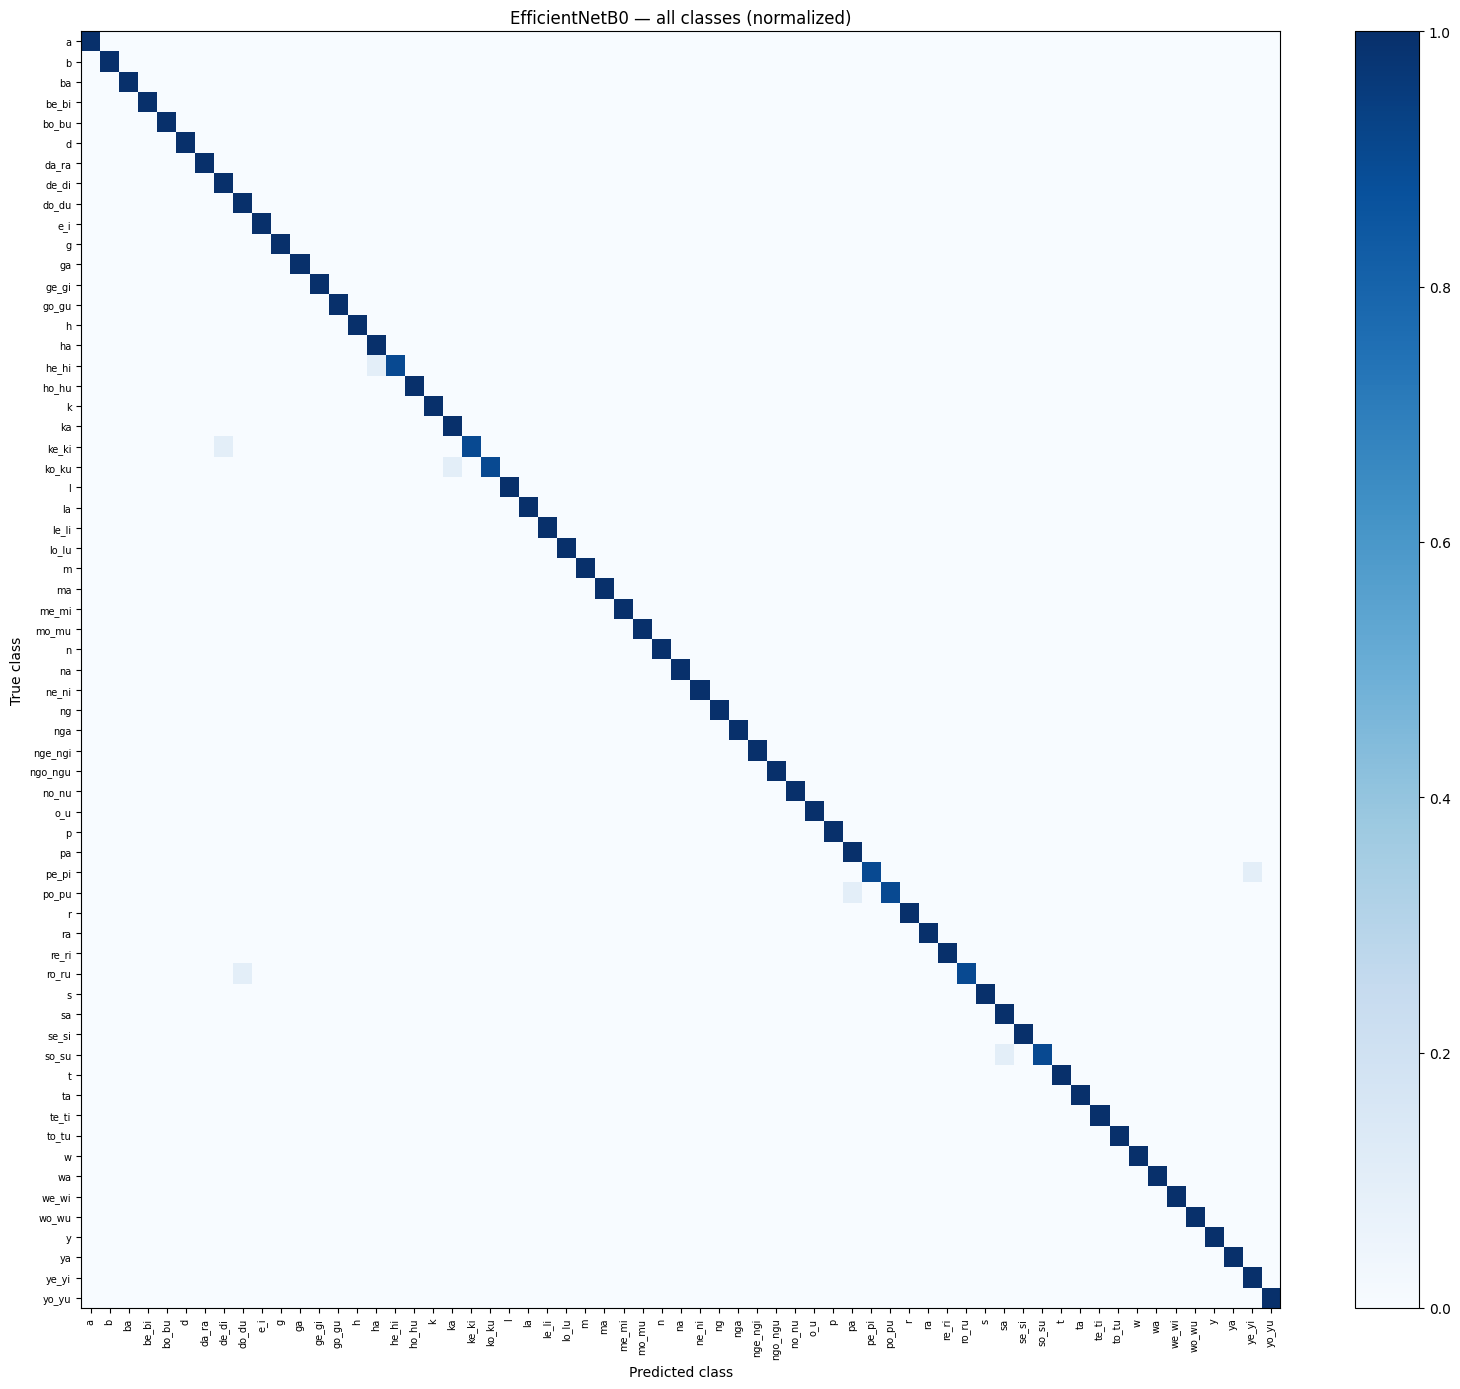

In [ ]:
# ============================================================
# STEP 18 — SEPARATE CONFUSION MATRICES
# EFFICIENTNETB0: EfficientNetB0
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# EXACT 63 BAYA CLASS GROUPS
# ============================================================

vowels = [
    "a",
    "e_i",
    "o_u",
]

base_consonants = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

a_forms = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

ei_forms = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

ou_forms = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]


# ============================================================
# DISPLAY-FRIENDLY CLASS NAMES
# ============================================================

display_names = {
    # Vowels
    "a": "a",
    "e_i": "e/i",
    "o_u": "o/u",

    # Base consonants
    "b": "b",
    "d": "d",
    "g": "g",
    "h": "h",
    "k": "k",
    "l": "l",
    "m": "m",
    "n": "n",
    "ng": "ng",
    "p": "p",
    "r": "r",
    "s": "s",
    "t": "t",
    "w": "w",
    "y": "y",

    # A forms
    "ba": "ba",
    "da_ra": "da/ra",
    "ga": "ga",
    "ha": "ha",
    "ka": "ka",
    "la": "la",
    "ma": "ma",
    "na": "na",
    "nga": "nga",
    "pa": "pa",
    "ra": "ra",
    "sa": "sa",
    "ta": "ta",
    "wa": "wa",
    "ya": "ya",

    # E/I forms
    "be_bi": "be/bi",
    "de_di": "de/di",
    "ge_gi": "ge/gi",
    "he_hi": "he/hi",
    "ke_ki": "ke/ki",
    "le_li": "le/li",
    "me_mi": "me/mi",
    "ne_ni": "ne/ni",
    "nge_ngi": "nge/ngi",
    "pe_pi": "pe/pi",
    "re_ri": "re/ri",
    "se_si": "se/si",
    "te_ti": "te/ti",
    "we_wi": "we/wi",
    "ye_yi": "ye/yi",

    # O/U forms
    "bo_bu": "bo/bu",
    "do_du": "do/du",
    "go_gu": "go/gu",
    "ho_hu": "ho/hu",
    "ko_ku": "ko/ku",
    "lo_lu": "lo/lu",
    "mo_mu": "mo/mu",
    "no_nu": "no/nu",
    "ngo_ngu": "ngo/ngu",
    "po_pu": "po/pu",
    "ro_ru": "ro/ru",
    "so_su": "so/su",
    "to_tu": "to/tu",
    "wo_wu": "wo/wu",
    "yo_yu": "yo/yu",
}


# ============================================================
# LABEL NAME → NUMERIC CLASS ID
# ============================================================

label_to_id = {
    id_to_label[i]: i
    for i in range(NUM_CLASSES)
}


# ============================================================
# VERIFY ALL GROUP LABELS EXIST
# ============================================================

all_group_labels = (
    vowels
    + base_consonants
    + a_forms
    + ei_forms
    + ou_forms
)

missing_from_dataset = [
    label
    for label in all_group_labels
    if label not in label_to_id
]

if missing_from_dataset:
    print("WARNING: These labels were not found in id_to_label:")
    for label in missing_from_dataset:
        print(" -", label)
else:
    print("✓ All grouped labels found in dataset.")


# ============================================================
# FUNCTION TO BUILD AND PLOT ONE GROUP MATRIX
# ============================================================

def plot_group_confusion_matrix(
    title,
    group_labels,
    normalized=False
):

    # --------------------------------------------------------
    # Numeric IDs for the selected group
    # --------------------------------------------------------

    group_labels = [label for label in group_labels if label in label_to_id]
    if not group_labels:
        print(f"Skipping {title}: no labels from this group in the dataset.")
        return np.zeros((0, 1), dtype=np.int32)

    group_ids = [
        label_to_id[label]
        for label in group_labels
    ]

    # --------------------------------------------------------
    # Select only samples whose TRUE label is in this group
    # --------------------------------------------------------

    mask = np.isin(
        y_test,
        group_ids
    )

    y_true_group = y_test[mask]
    y_pred_group = y_pred[mask]

    n_classes = len(group_labels)

    # --------------------------------------------------------
    # Matrix dimensions:
    #
    # rows    = true classes in this group
    # columns = predicted classes in this group + Other
    # --------------------------------------------------------

    cm_group = np.zeros(
        (
            n_classes,
            n_classes + 1
        ),
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Numeric class ID → position inside this group
    # --------------------------------------------------------

    id_to_position = {
        class_id: position
        for position, class_id
        in enumerate(group_ids)
    }

    # --------------------------------------------------------
    # Fill matrix
    # --------------------------------------------------------

    for true_id, pred_id in zip(
        y_true_group,
        y_pred_group
    ):

        row = id_to_position[
            int(true_id)
        ]

        # Prediction belongs to same group
        if int(pred_id) in id_to_position:

            col = id_to_position[
                int(pred_id)
            ]

        # Prediction belongs to another group
        else:

            col = n_classes

        cm_group[row, col] += 1


    # ========================================================
    # NORMALIZATION OPTION
    # ========================================================

    if normalized:

        row_totals = cm_group.sum(
            axis=1,
            keepdims=True
        )

        matrix_to_plot = np.divide(
            cm_group,
            row_totals,
            out=np.zeros_like(
                cm_group,
                dtype=float
            ),
            where=row_totals != 0
        )

        colorbar_label = "Proportion"

    else:

        matrix_to_plot = cm_group

        colorbar_label = "Number of Samples"


    # ========================================================
    # DISPLAY LABELS
    # ========================================================

    true_display_labels = [
        display_names.get(
            label,
            label
        )
        for label in group_labels
    ]

    predicted_display_labels = (
        true_display_labels
        + ["Other"]
    )


    # ========================================================
    # FIGURE SIZE
    # ========================================================

    figure_width = max(
        7,
        (n_classes + 1) * 0.65
    )

    figure_height = max(
        5,
        n_classes * 0.55
    )


    # ========================================================
    # PLOT
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(
            figure_width,
            figure_height
        )
    )

    im = ax.imshow(
    matrix_to_plot,
    interpolation="nearest",
    aspect="auto",
    cmap="Blues"
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=15
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=11
    )

    ax.set_ylabel(
        "True Class",
        fontsize=11
    )


    # --------------------------------------------------------
    # X-axis labels
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(
            n_classes + 1
        )
    )

    ax.set_xticklabels(
        predicted_display_labels,
        rotation=90,
        fontsize=9
    )


    # --------------------------------------------------------
    # Y-axis labels
    # --------------------------------------------------------

    ax.set_yticks(
        np.arange(
            n_classes
        )
    )

    ax.set_yticklabels(
        true_display_labels,
        fontsize=9
    )


    # --------------------------------------------------------
    # Color bar
    # --------------------------------------------------------

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label=colorbar_label
    )

    # ========================================================
    # WRITE VALUES INSIDE EACH CELL
    # White text on dark blue cells
    # Black text on light blue cells
    # ========================================================

    max_value = matrix_to_plot.max()

    # Threshold can be adjusted if needed
    threshold = max_value * 0.50

    for row in range(n_classes):

        for col in range(n_classes + 1):

            value = matrix_to_plot[row, col]

            if normalized:

                cell_text = (
                    f"{value:.2f}"
                    if value > 0
                    else ""
                )

            else:

                cell_text = (
                    str(int(value))
                    if value > 0
                    else ""
                )

            if cell_text:

                text_color = (
                    "white"
                    if value >= threshold
                    else "black"
                )

                ax.text(
                    col,
                    row,
                    cell_text,
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color,
                    fontweight="bold"
                )


    # ========================================================
    # GRID LINES
    # ========================================================

    ax.set_xticks(
        np.arange(
            -0.5,
            n_classes + 1,
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            n_classes,
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        linestyle="-",
        linewidth=0.3,
        alpha=0.3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


    plt.tight_layout()
    safe_title = "".join(ch if ch.isalnum() else "_" for ch in title).strip("_")
    suffix = "normalized" if normalized else "counts"
    fig.savefig(OUTPUT_DIR / f"{safe_title}_{suffix}.png", dpi=160, bbox_inches="tight")
    plt.show()


    # ========================================================
    # BASIC GROUP STATISTICS
    # ========================================================

    total_samples = cm_group.sum()

    correct_predictions = sum(
        cm_group[i, i]
        for i in range(
            n_classes
        )
    )

    cross_group_errors = cm_group[
        :,
        -1
    ].sum()

    group_accuracy = (
        correct_predictions
        / total_samples
        if total_samples > 0
        else 0
    )

    print(
        f"\n{title}"
    )

    print(
        f"Samples: {total_samples}"
    )

    print(
        f"Correct predictions: "
        f"{correct_predictions}"
    )

    print(
        f"Cross-group errors: "
        f"{cross_group_errors}"
    )

    print(
        f"Group accuracy: "
        f"{group_accuracy:.4f} "
        f"({group_accuracy * 100:.2f}%)"
    )

    print(
        "-" * 60
    )


    return cm_group


# ============================================================
# 1. VOWELS CONFUSION MATRIX
# ============================================================

cm_vowels = plot_group_confusion_matrix(
    title=(
        "EfficientNetB0 — Vowels Confusion Matrix"
    ),
    group_labels=vowels,
    normalized=False
)


# ============================================================
# 2. BASE CONSONANTS CONFUSION MATRIX
# ============================================================

cm_base_consonants = plot_group_confusion_matrix(
    title=(
        "EfficientNetB0 — Base Consonants Confusion Matrix"
    ),
    group_labels=base_consonants,
    normalized=False
)


# ============================================================
# 3. A-FORM CONFUSION MATRIX
# ============================================================

cm_a_forms = plot_group_confusion_matrix(
    title=(
        "EfficientNetB0 — A Form Confusion Matrix"
    ),
    group_labels=a_forms,
    normalized=False
)


# ============================================================
# 4. E/I-FORM CONFUSION MATRIX
# ============================================================

cm_ei_forms = plot_group_confusion_matrix(
    title=(
        "EfficientNetB0 — E/I Form Confusion Matrix"
    ),
    group_labels=ei_forms,
    normalized=False
)


# ============================================================
# 5. O/U-FORM CONFUSION MATRIX
# ============================================================

cm_ou_forms = plot_group_confusion_matrix(
    title=(
        "EfficientNetB0 — O/U Form Confusion Matrix"
    ),
    group_labels=ou_forms,
    normalized=False
)


# ============================================================
# FINAL MESSAGE
# ============================================================

print("\n" + "=" * 65)
print("EFFICIENTNETB0 — SEPARATE CONFUSION MATRICES COMPLETE")
print("=" * 65)

print("Generated matrices:")
print("1. Vowels")
print("2. Base Consonants")
print("3. A Forms")
print("4. E/I Forms")
print("5. O/U Forms")


class_groups = {
    "Vowels": vowels, "Base consonants": base_consonants,
    "A forms": a_forms, "E_I forms": ei_forms, "O_U forms": ou_forms,
}
group_metrics = []
for group_name, names in class_groups.items():
    present = [name for name in names if name in label_to_id]
    if not present:
        continue
    plot_group_confusion_matrix(group_name, present, normalized=True)
    group_ids = [label_to_id[name] for name in present]
    mask = np.isin(y_test, group_ids)
    group_metrics.append({
        "group": group_name, "samples": int(mask.sum()),
        "accuracy": float(np.mean(y_test[mask] == y_pred[mask])) if mask.any() else None,
        "macro_precision": float(np.mean([report[name]["precision"] for name in present])),
        "macro_recall": float(np.mean([report[name]["recall"] for name in present])),
        "macro_f1": float(np.mean([report[name]["f1-score"] for name in present])),
    })
pd.DataFrame(group_metrics).to_csv(OUTPUT_DIR / "group_metrics.csv", index=False)

cm_all = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
row_totals = cm_all.sum(axis=1, keepdims=True)
cm_normalized = np.divide(cm_all, row_totals, out=np.zeros_like(cm_all, dtype=float),
                          where=row_totals != 0)
for matrix, suffix in [(cm_all, "counts"), (cm_normalized, "normalized")]:
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
        OUTPUT_DIR / f"confusion_matrix_all_{suffix}.csv"
    )
    fig, ax = plt.subplots(figsize=(16, 14))
    im = ax.imshow(matrix, cmap="Blues", aspect="auto")
    ax.set_xticks(np.arange(NUM_CLASSES), classes, rotation=90, fontsize=7)
    ax.set_yticks(np.arange(NUM_CLASSES), classes, fontsize=7)
    ax.set(xlabel="Predicted class", ylabel="True class",
           title=f"EfficientNetB0 — all classes ({suffix})")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"confusion_matrix_all_{suffix}.png", dpi=160)
    plt.show()


## Step 18 — Measure inference time


In [ ]:
# Includes Keras predict overhead, for consistency with the original workflow.
for _ in range(3):
    _ = best_model.predict(Ximg_test[:1], verbose=0)
timings_ms = []
n_timing = min(100, len(y_test))
for i in range(n_timing):
    start = time.perf_counter()
    _ = best_model.predict(Ximg_test[i:i+1], verbose=0)
    timings_ms.append((time.perf_counter() - start) * 1000)
mean_inference_ms = float(np.mean(timings_ms))
median_inference_ms = float(np.median(timings_ms))
print(f"Mean single-image inference: {mean_inference_ms:.2f} ms")
print(f"Median single-image inference: {median_inference_ms:.2f} ms")

std_inference_ms = float(np.std(timings_ms, ddof=1)) if len(timings_ms) > 1 else None
p95_inference_ms = float(np.percentile(timings_ms, 95))
print("Inference sample standard deviation (ms):", std_inference_ms)
print(f"95th percentile inference: {p95_inference_ms:.2f} ms")
pd.DataFrame({"sample_index": range(n_timing), "inference_ms": timings_ms}).to_csv(
    OUTPUT_DIR / "inference_timings.csv", index=False
)


Mean single-image inference: 75.64 ms
Median single-image inference: 73.97 ms
Inference sample standard deviation (ms): 7.007398496656254
95th percentile inference: 85.63 ms


## Step 19 — Save the final model, label mapping, preprocessing configuration, and metrics


In [ ]:
best_model.save(FINAL_MODEL_PATH)

label_mapping_path = OUTPUT_DIR / f"{MODEL_NAME}_labels_{MODEL_VERSION}.json"
with open(label_mapping_path, "w", encoding="utf-8") as f:
    json.dump({
        "label_to_id": label_to_id,
        "id_to_label": {str(k): v for k, v in id_to_label.items()},
    }, f, ensure_ascii=False, indent=2)

preprocessing = {
    "input": "image_only",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "image_channels": IMG_CHANNELS,
    "image_dtype": "float32",
    "image_range": [0.0, 1.0],
    "image_background_rule": "white background is 0; black ink is 1",
    "image_position_scale_normalization": "ink bounding box -> proportional padding -> centered square -> bilinear resize",
    "image_padding_ratio": IMAGE_PADDING_RATIO,
    "ink_threshold": INK_THRESHOLD,
    "backbone": "EfficientNetB0",
    "backbone_weights": BACKBONE_WEIGHTS, "training_regime": TRAINING_REGIME,
    "internal_adapter": "repeat grayscale to RGB -> 255*(1-ink) -> built-in EfficientNetB0 rescaling",
    "seed": SEED,
    "augmentation": {
        "enabled": AUGMENTATION_ENABLED,
        "training_only": True,
        "rotation_degrees": AUG_ROTATION_DEGREES,
        "uniform_scale_range": list(AUG_SCALE_RANGE),
        "translation_fraction": AUG_TRANSLATION_FRACTION,
        "probability": AUG_PROBABILITY,
        "seed": SEED,
        "policy": "preserve all ink; no flips, cropping, or erasing",
    },
    "group_split": {
        "train_exports": train_groups,
        "validation_exports": val_groups,
        "test_exports": test_groups,
    },
    "tensorflow_version": tf.__version__,
}
preprocess_path = OUTPUT_DIR / f"{MODEL_NAME}_preprocessing_{MODEL_VERSION}.json"
with open(preprocess_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing, f, indent=2)

model_size_mb = FINAL_MODEL_PATH.stat().st_size / (1024 * 1024)
metrics = {
    "model": "EfficientNetB0 (image only)", "version": MODEL_VERSION,
    "accuracy": float(accuracy), "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall), "macro_f1": float(macro_f1),
    "mean_inference_ms": mean_inference_ms,
    "median_inference_ms": median_inference_ms,
    "model_size_mb": float(model_size_mb), "num_classes": int(NUM_CLASSES),
    "train_samples": int(len(y_train)), "validation_samples": int(len(y_val)),
    "test_samples": int(len(y_test)),
    "training_regime": TRAINING_REGIME, "pretrained_weights": BACKBONE_WEIGHTS,
    "early_stopping": False, "warmup_epoch_budget": WARMUP_EPOCHS if BACKBONE_WEIGHTS else 0,
    "seed": SEED, "input_resolution": f"{IMG_HEIGHT}x{IMG_WIDTH}",
    "parameters": int(best_model.count_params()),
    "best_epoch": best_epoch, "best_validation_loss": best_validation_loss,
    "best_validation_accuracy": best_validation_accuracy,
    "epochs_executed": len(training_stages), "training_seconds": training_seconds,
    "std_inference_ms": std_inference_ms, "p95_inference_ms": p95_inference_ms,
    "inference_samples": n_timing,
    "latency_method": "single-image model.predict; 3 warmups; includes predict overhead",
    "tensorflow_version": tf.__version__,
    "devices": [str(device) for device in tf.config.list_physical_devices()],
}
metrics_path = OUTPUT_DIR / f"{MODEL_NAME}_metrics_{MODEL_VERSION}.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
history_table = pd.DataFrame(history.history)
history_table.insert(0, "epoch", np.arange(1, len(training_stages) + 1))
history_table.insert(1, "stage", training_stages)
history_table.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "model_comparison_row.csv", index=False)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "classification_report.csv")
predictions = test_df[["source_export", "attempt_id", "label", "image_path"]].copy()
predictions["predicted_label"] = [id_to_label[int(i)] for i in y_pred]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)
print(f"Final model size: {model_size_mb:.2f} MB")


Saved files:
 - A_forms_normalized.png
 - Base_consonants_normalized.png
 - Baybayin_EfficientNetB0_imagenet_finetuned_1.0.keras
 - Baybayin_EfficientNetB0_imagenet_finetuned_cp_1.0.keras
 - Baybayin_EfficientNetB0_imagenet_finetuned_finetune_1.0.keras
 - Baybayin_EfficientNetB0_imagenet_finetuned_labels_1.0.json
 - Baybayin_EfficientNetB0_imagenet_finetuned_metrics_1.0.json
 - Baybayin_EfficientNetB0_imagenet_finetuned_preprocessing_1.0.json
 - Baybayin_EfficientNetB0_imagenet_finetuned_warmup_1.0.keras
 - E_I_forms_normalized.png
 - EfficientNetB0___A_Form_Confusion_Matrix_counts.png
 - EfficientNetB0___Base_Consonants_Confusion_Matrix_counts.png
 - EfficientNetB0___E_I_Form_Confusion_Matrix_counts.png
 - EfficientNetB0___O_U_Form_Confusion_Matrix_counts.png
 - EfficientNetB0___Vowels_Confusion_Matrix_counts.png
 - O_U_forms_normalized.png
 - Vowels_normalized.png
 - classification_report.csv
 - confusion_matrix_all_counts.csv
 - confusion_matrix_all_counts.png
 - confusion_matrix_al

## Step 20 — Download all EfficientNetB0 artifacts


In [ ]:
archive_base = WORK_DIR / f"{MODEL_NAME}_{MODEL_VERSION}_artifacts"
archive_path = shutil.make_archive(str(archive_base), "zip", root_dir=OUTPUT_DIR)
print("Created:", archive_path)
if files is not None:
    files.download(archive_path)
else:
    print("Model artifacts are available at the path above.")


Created: /content/Baybayin_EfficientNetB0_imagenet_finetuned_1.0_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def get_all_layers(model):
    """Collect nested layers without counting shared layers twice."""
    collected = []
    seen = set()

    def visit(parent):
        for layer in parent.layers:
            if id(layer) in seen:
                continue

            seen.add(id(layer))
            collected.append(layer)

            if isinstance(layer, tf.keras.Model):
                visit(layer)

    visit(model)
    return collected


all_layers = get_all_layers(model)

standard_convs = sum(
    isinstance(layer, layers.Conv2D)
    for layer in all_layers
)

depthwise_convs = sum(
    isinstance(layer, layers.DepthwiseConv2D)
    for layer in all_layers
)

best_index = int(np.argmin(history.history["val_loss"]))

print("Standard Conv2D layers:", standard_convs)
print("Depthwise Conv2D layers:", depthwise_convs)
print("Total convolution layers:", standard_convs + depthwise_convs)
print("Best epoch:", best_index + 1)
print("Best validation loss:", history.history["val_loss"][best_index])
print(
    "Validation accuracy at best epoch:",
    history.history["val_accuracy"][best_index],
)
print("Parameters:", model.count_params())

Standard Conv2D layers: 65
Depthwise Conv2D layers: 16
Total convolution layers: 81
Best epoch: 34
Best validation loss: 0.11033754050731659
Validation accuracy at best epoch: 0.9698412418365479
Parameters: 4221666


In [ ]:
# ============================================================
# STEP 17A — PREDICT AND CALCULATE TEST METRICS
# Custom CNN-BiLSTM
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
)

# ------------------------------------------------------------
# 1. Predict using BOTH model inputs
# ------------------------------------------------------------

y_pred_prob = model.predict(
    {
        "image_input": Ximg_test,
    },
    batch_size=BATCH_SIZE,
    verbose=1,
)

# Convert softmax probabilities to predicted class IDs
y_pred = np.argmax(y_pred_prob, axis=1)


# ------------------------------------------------------------
# 2. Overall test metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )
)


# ------------------------------------------------------------
# 3. Display overall results
# ------------------------------------------------------------

print("=" * 60)
print("CUSTOM CNN-BiLSTM — TEST RESULTS")
print("=" * 60)

print(f"Test samples:     {len(y_test)}")
print(f"Accuracy:         {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision:  {macro_precision:.4f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall:     {macro_recall:.4f} ({macro_recall * 100:.2f}%)")
print(f"Macro F1-score:   {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: image_input
Received: inputs=['Tensor(shape=(32, 96, 96, 1))']
  warnings.warn(msg)


16/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: image_input
Received: inputs=['Tensor(shape=(None, 96, 96, 1))']
  warnings.warn(msg)


20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 324ms/step
CUSTOM CNN-BiLSTM — TEST RESULTS
Test samples:     630
Accuracy:         0.9921 (99.21%)
Macro Precision:  0.9928 (99.28%)
Macro Recall:     0.9921 (99.21%)
Macro F1-score:   0.9920 (99.20%)


In [ ]:
# ============================================================
# BAYA SPLIT CLASS-BALANCE AUDIT
# Verify class counts in train / validation / test
# ============================================================

EXPECTED_SPLIT_COUNTS = {
    "train": 50,
    "validation": 10,
    "test": 10,
}


def audit_split_class_counts(
    part_df,
    split_name,
    expected_per_class,
):
    counts = (
        part_df["label"]
        .astype(str)
        .value_counts()
        .reindex(sorted(EXPECTED_LABELS), fill_value=0)
    )

    result = pd.DataFrame({
        "class": counts.index,
        "actual": counts.values,
    })

    result["expected"] = expected_per_class

    result["difference"] = (
        result["actual"] - result["expected"]
    )

    result["status"] = np.where(
        result["actual"] == result["expected"],
        "OK",
        "CHECK",
    )

    print("\n" + "=" * 65)
    print(f"{split_name.upper()} CLASS COUNTS")
    print("=" * 65)

    display(result)

    bad = result[result["status"] != "OK"]

    if bad.empty:
        print(
            f"✓ Every class has exactly "
            f"{expected_per_class} samples."
        )
    else:
        print("✗ Class-balance problem found:")
        display(bad)

    return result


train_class_audit = audit_split_class_counts(
    train_df,
    "train",
    EXPECTED_SPLIT_COUNTS["train"],
)

val_class_audit = audit_split_class_counts(
    val_df,
    "validation",
    EXPECTED_SPLIT_COUNTS["validation"],
)

test_class_audit = audit_split_class_counts(
    test_df,
    "test",
    EXPECTED_SPLIT_COUNTS["test"],
)


TRAIN CLASS COUNTS


,class,actual,expected,difference,status
0,a,50,50,0,OK
1,b,50,50,0,OK
2,ba,50,50,0,OK
3,be_bi,50,50,0,OK
4,bo_bu,50,50,0,OK
...,...,...,...,...,...
58,wo_wu,50,50,0,OK
59,y,50,50,0,OK
60,ya,50,50,0,OK
61,ye_yi,50,50,0,OK


✓ Every class has exactly 50 samples.

VALIDATION CLASS COUNTS


,class,actual,expected,difference,status
0,a,10,10,0,OK
1,b,10,10,0,OK
2,ba,10,10,0,OK
3,be_bi,10,10,0,OK
4,bo_bu,10,10,0,OK
...,...,...,...,...,...
58,wo_wu,10,10,0,OK
59,y,10,10,0,OK
60,ya,10,10,0,OK
61,ye_yi,10,10,0,OK


✓ Every class has exactly 10 samples.

TEST CLASS COUNTS


,class,actual,expected,difference,status
0,a,10,10,0,OK
1,b,10,10,0,OK
2,ba,10,10,0,OK
3,be_bi,10,10,0,OK
4,bo_bu,10,10,0,OK
...,...,...,...,...,...
58,wo_wu,10,10,0,OK
59,y,10,10,0,OK
60,ya,10,10,0,OK
61,ye_yi,10,10,0,OK


✓ Every class has exactly 10 samples.


In [ ]:
# ============================================================
# BAYA CLASS-INDEX MAPPING AUDIT
# Verify output index -> class name
# ============================================================

print("=" * 70)
print("MODEL OUTPUT INDEX → DATASET CLASS")
print("=" * 70)

mapping_table = pd.DataFrame({
    "index": list(range(NUM_CLASSES)),
    "class": [
        id_to_label[i]
        for i in range(NUM_CLASSES)
    ],
})

display(mapping_table)

assert len(mapping_table) == NUM_CLASSES
assert mapping_table["class"].is_unique

print(f"✓ {NUM_CLASSES} unique model output labels.")

# ------------------------------------------------------------
# Inspect the K family specifically
# ------------------------------------------------------------

K_FAMILY = [
    "k",
    "ke_ki",
    "ko_ku",
]

print("\nK-FAMILY MODEL INDICES")

for label in K_FAMILY:
    if label in label_to_id:
        print(
            f"{label:10s} -> index {label_to_id[label]}"
        )
    else:
        print(
            f"{label:10s} -> MISSING"
        )

MODEL OUTPUT INDEX → DATASET CLASS


,index,class
0,0,a
1,1,b
2,2,ba
3,3,be_bi
4,4,bo_bu
...,...,...
58,58,wo_wu
59,59,y
60,60,ya
61,61,ye_yi


✓ 63 unique model output labels.

K-FAMILY MODEL INDICES
k          -> index 18
ke_ki      -> index 20
ko_ku      -> index 21


In [ ]:
# ============================================================
# VISUAL CLASS AUDIT
# Show all raw OR preprocessed samples for one class
# ============================================================

import math
import matplotlib.pyplot as plt
from PIL import Image


def show_all_class_samples(
    class_name,
    columns=10,
    preprocessed=False,
):
    rows_df = (
        df[
            df["label"].astype(str)
            == class_name
        ]
        .sort_values(
            ["source_export", "attempt_id"]
        )
        .reset_index(drop=True)
    )

    n = len(rows_df)

    print("=" * 65)
    print(f"CLASS: {class_name}")
    print(f"SAMPLES: {n}")
    print("=" * 65)

    if n == 0:
        print("No samples found.")
        return

    rows = math.ceil(n / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(
            columns * 2,
            rows * 2.3,
        ),
    )

    axes = np.asarray(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")

        if i >= n:
            continue

        record = rows_df.iloc[i]

        if preprocessed:
            image = load_image_array(
                record["image_path"]
            )[..., 0]

            ax.imshow(
                image,
                cmap="gray",
                vmin=0,
                vmax=1,
            )

        else:
            image = Image.open(
                record["image_path"]
            ).convert("RGBA")

            background = Image.new(
                "RGBA",
                image.size,
                (255, 255, 255, 255),
            )

            background.alpha_composite(image)

            ax.imshow(
                background.convert("L"),
                cmap="gray",
            )

        ax.set_title(
            f"{record['source_export'][-8:]}\n"
            f"{record['attempt_id']}",
            fontsize=7,
        )

    mode = (
        "PREPROCESSED"
        if preprocessed
        else "RAW"
    )

    fig.suptitle(
        f"{class_name.upper()} — {mode}",
        fontsize=16,
    )

    plt.tight_layout()
    plt.show()

CLASS: k
SAMPLES: 70


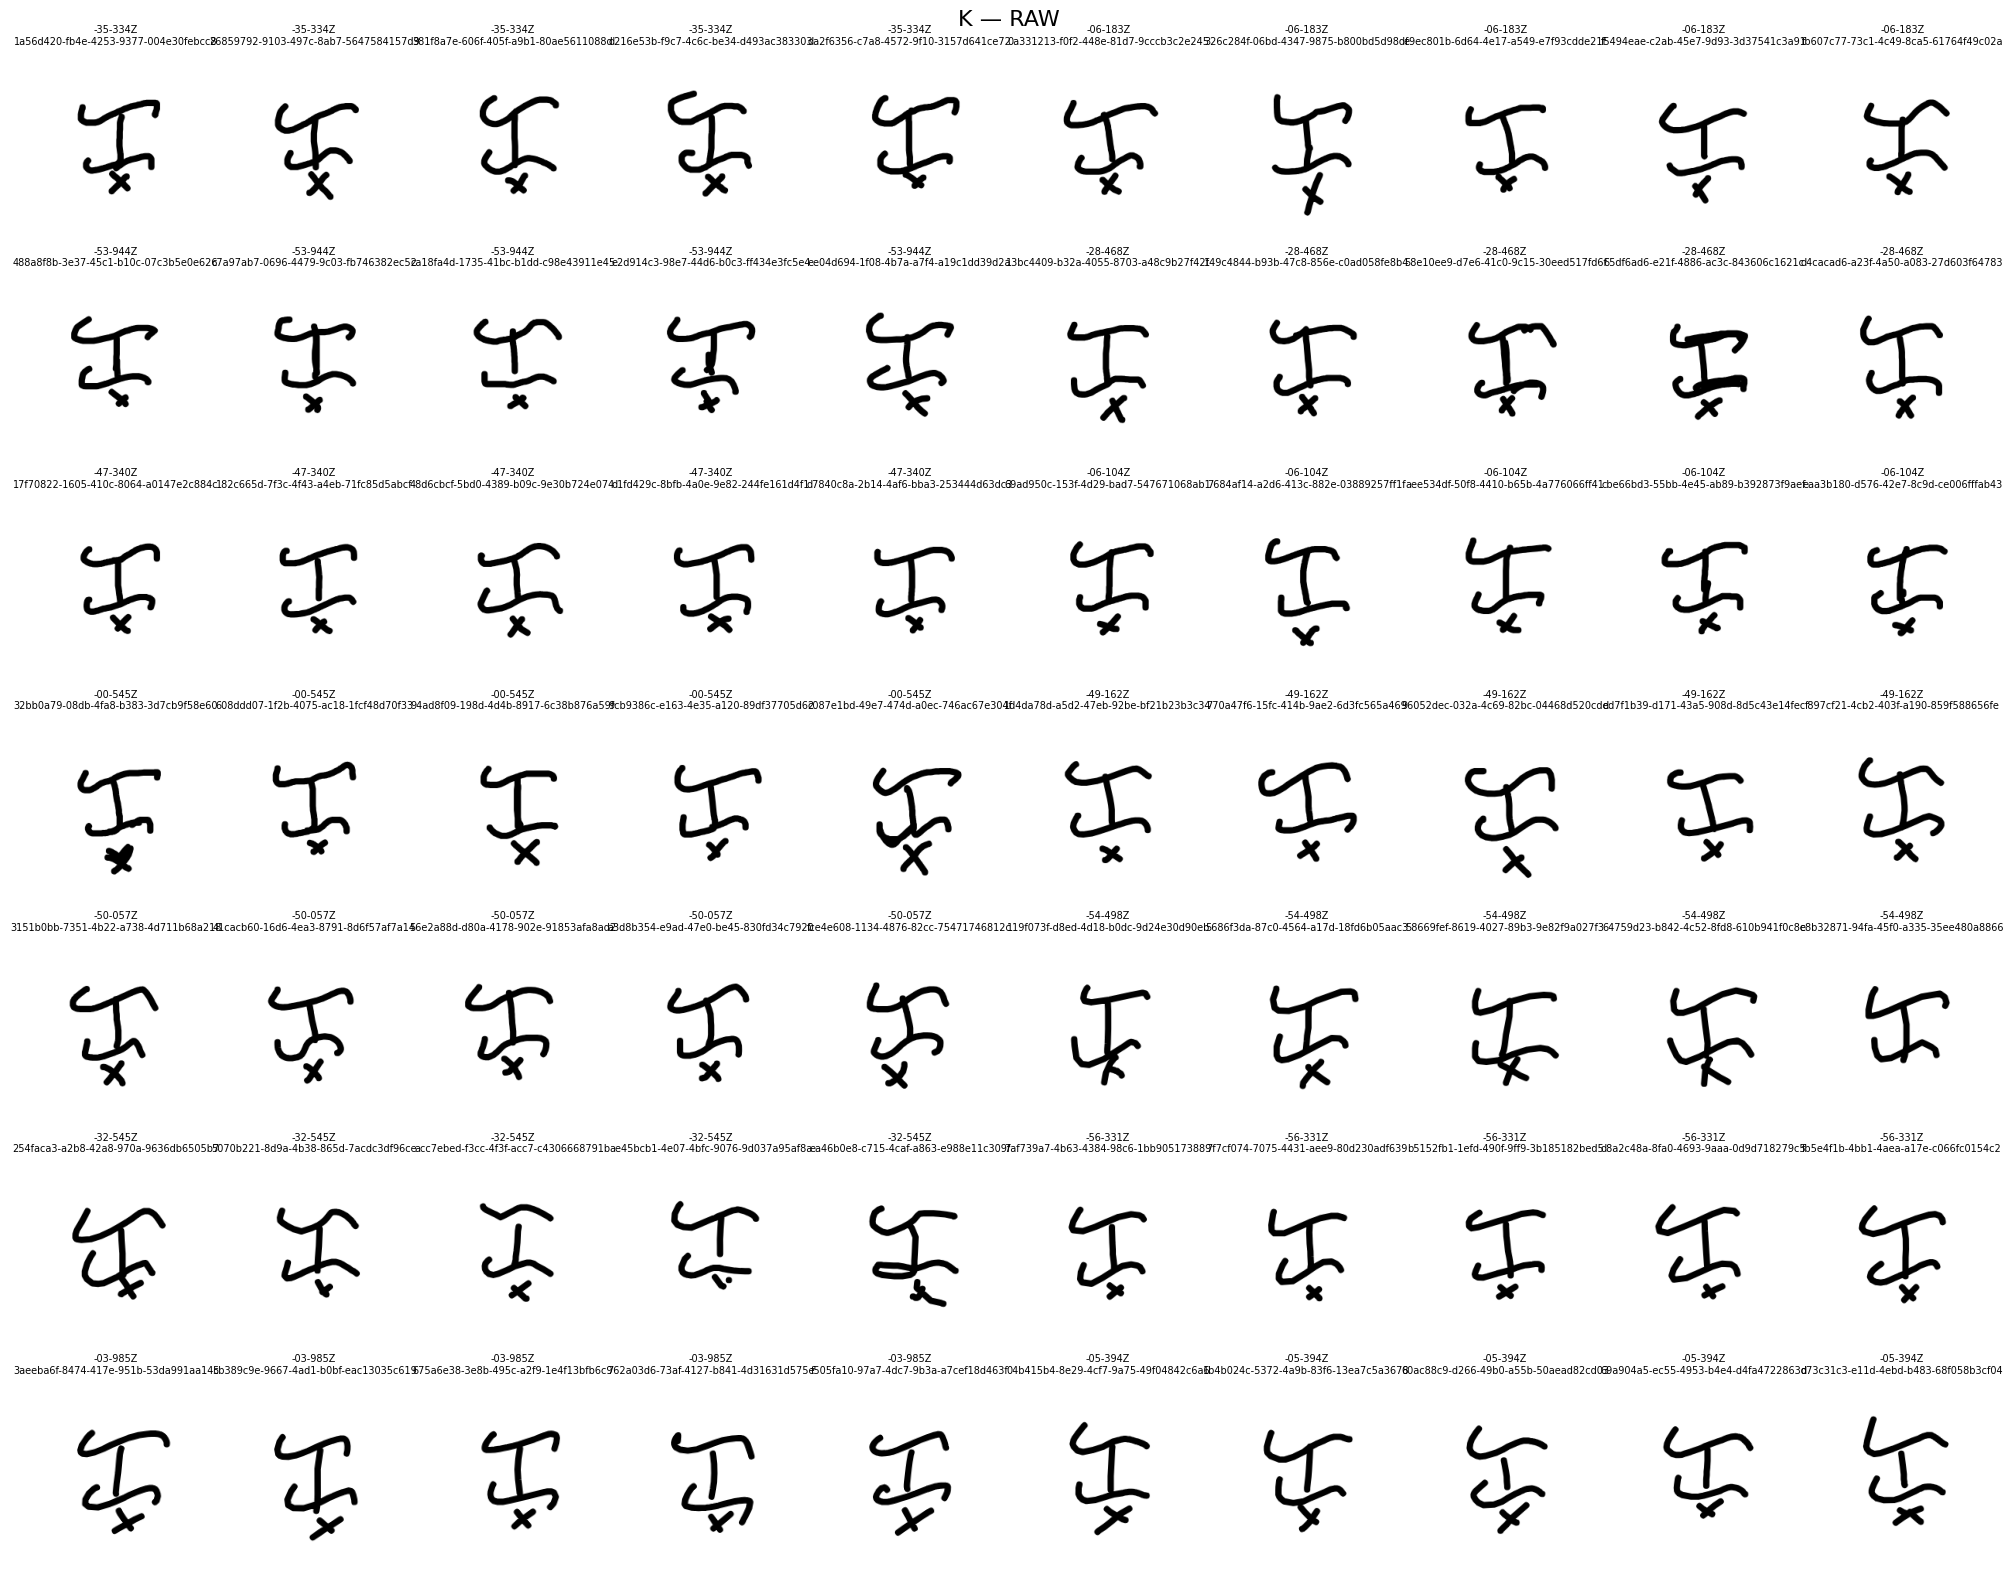

CLASS: ka
SAMPLES: 70


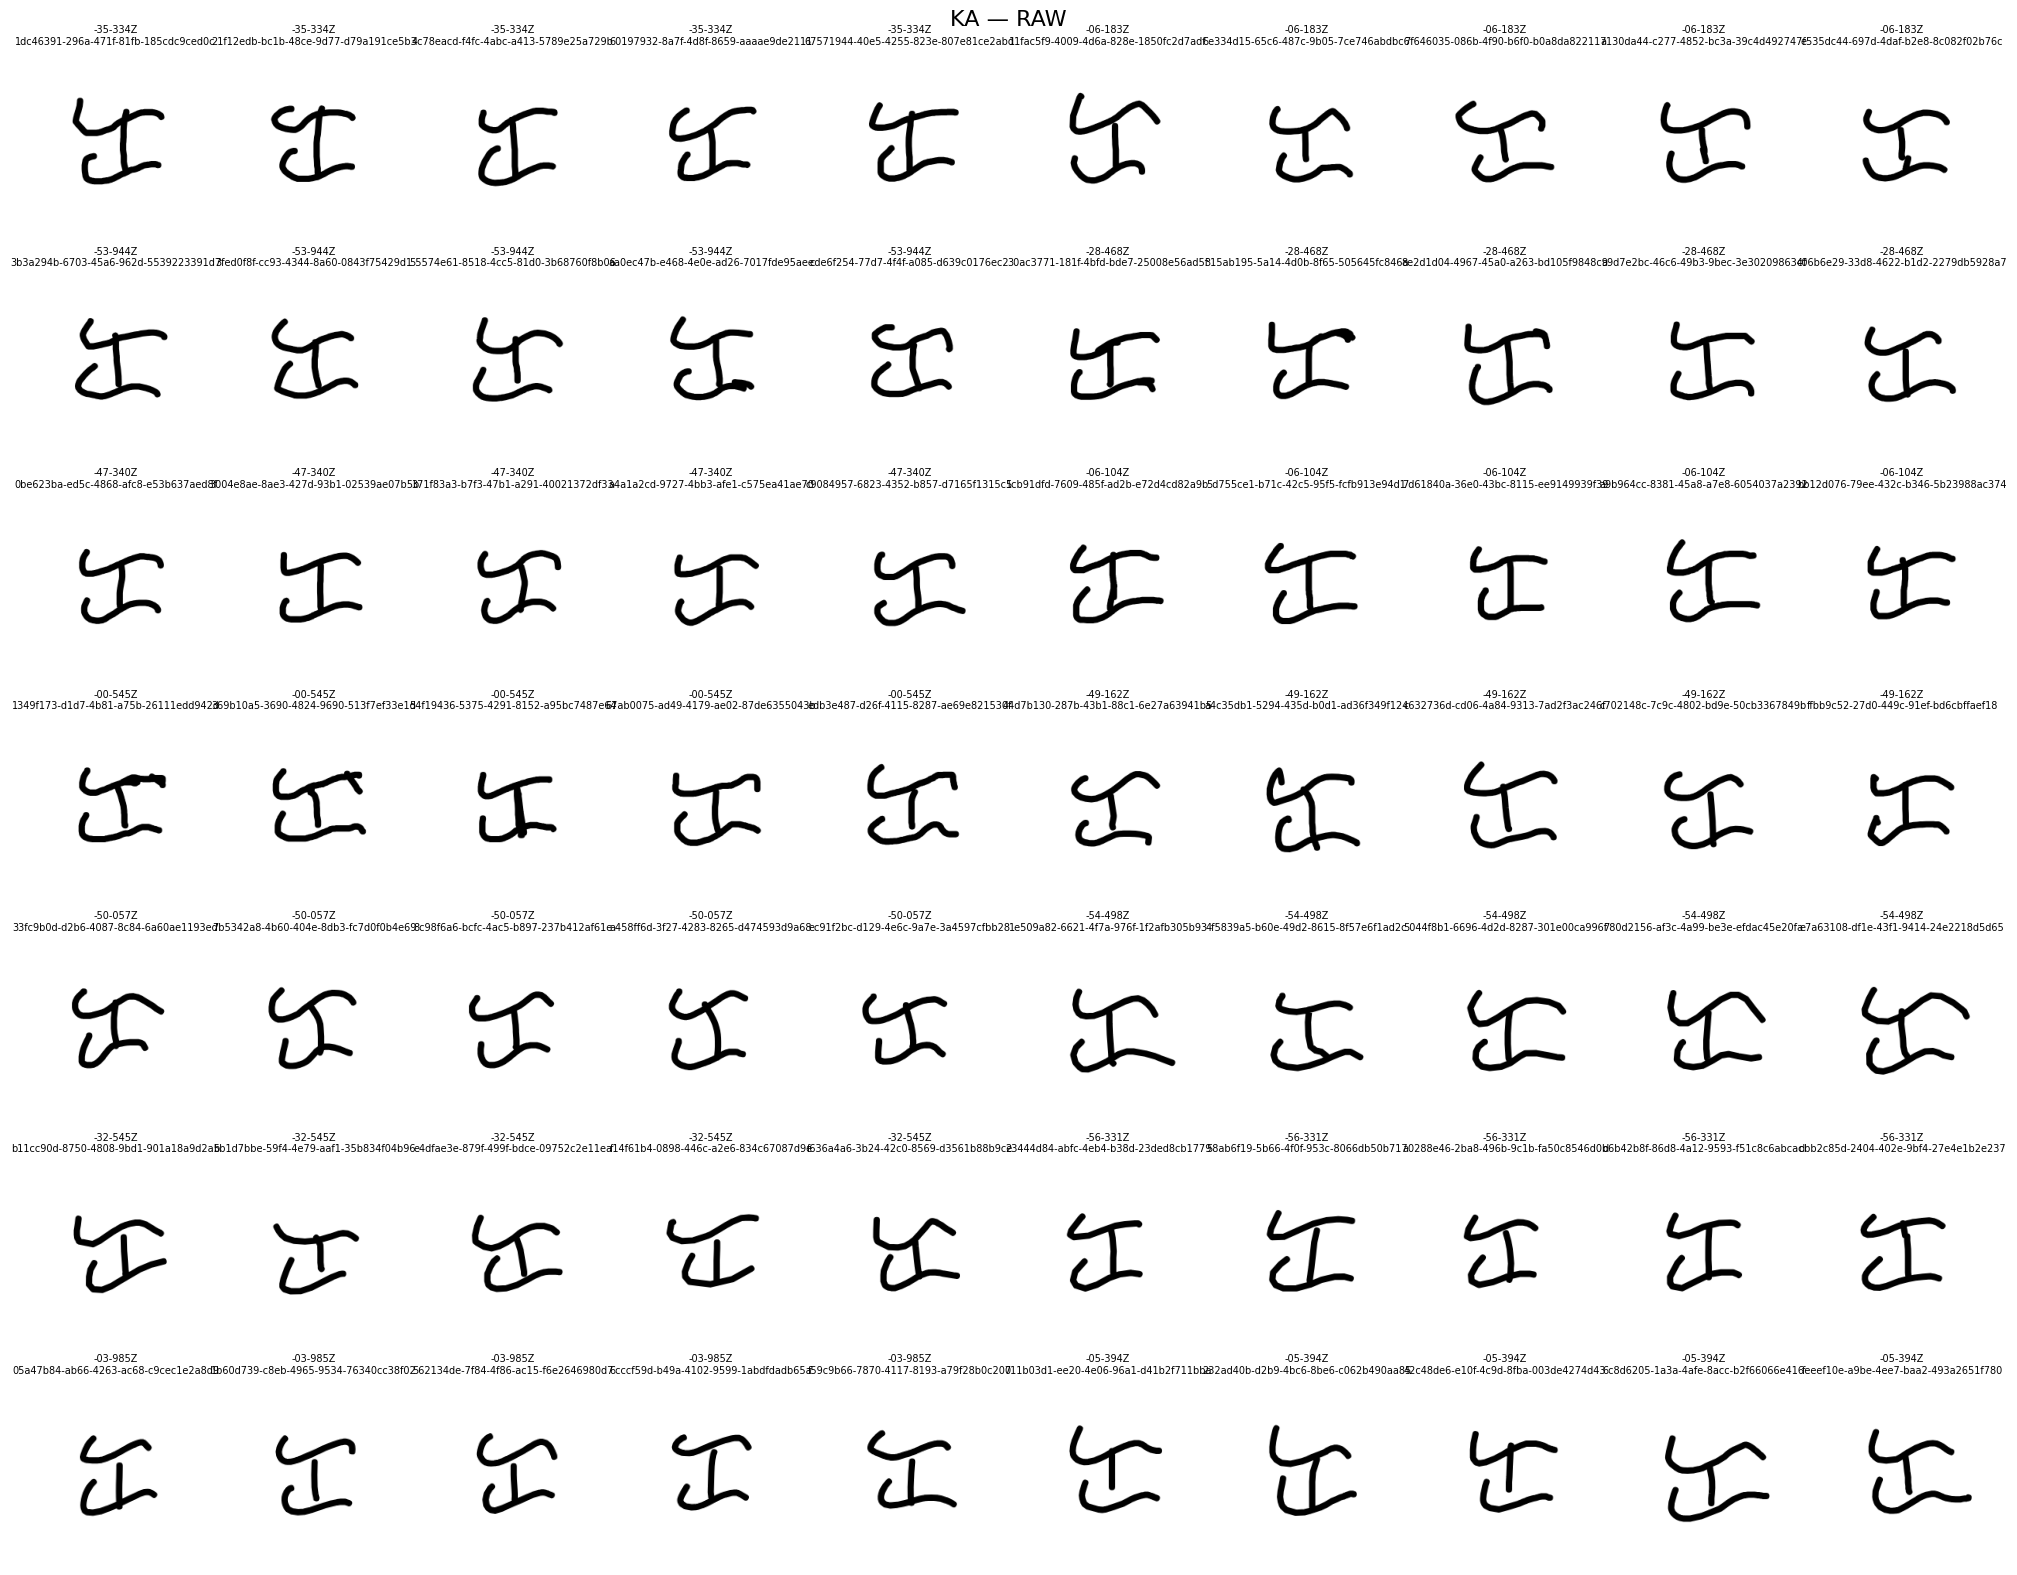

CLASS: ke_ki
SAMPLES: 70


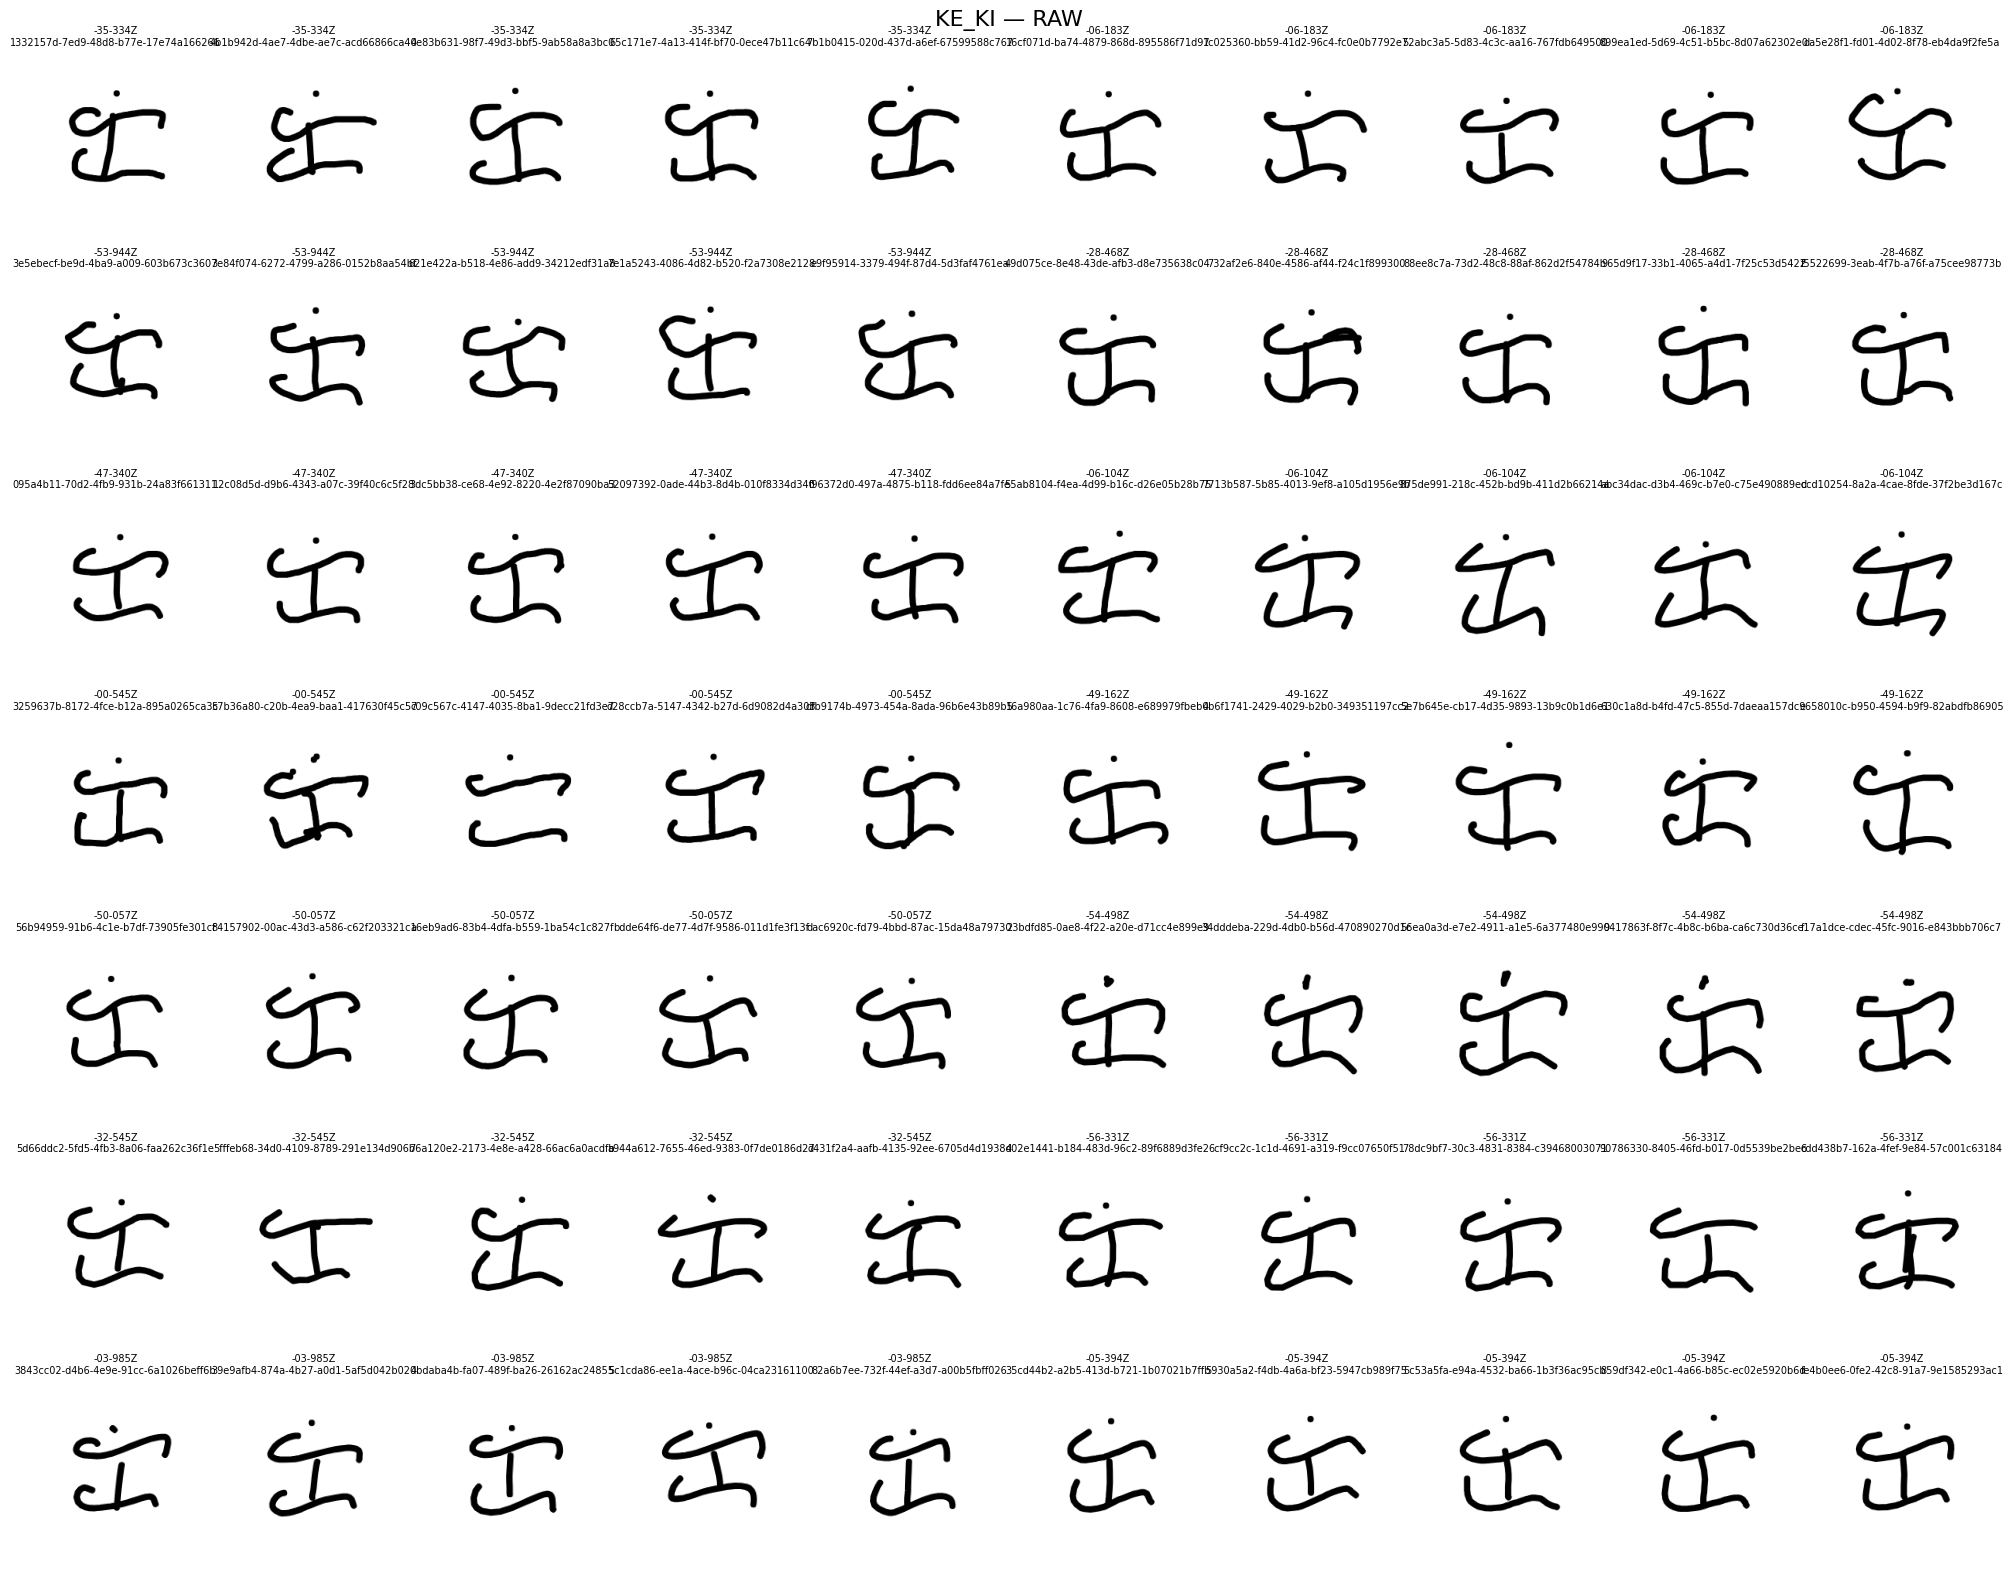

CLASS: ko_ku
SAMPLES: 70


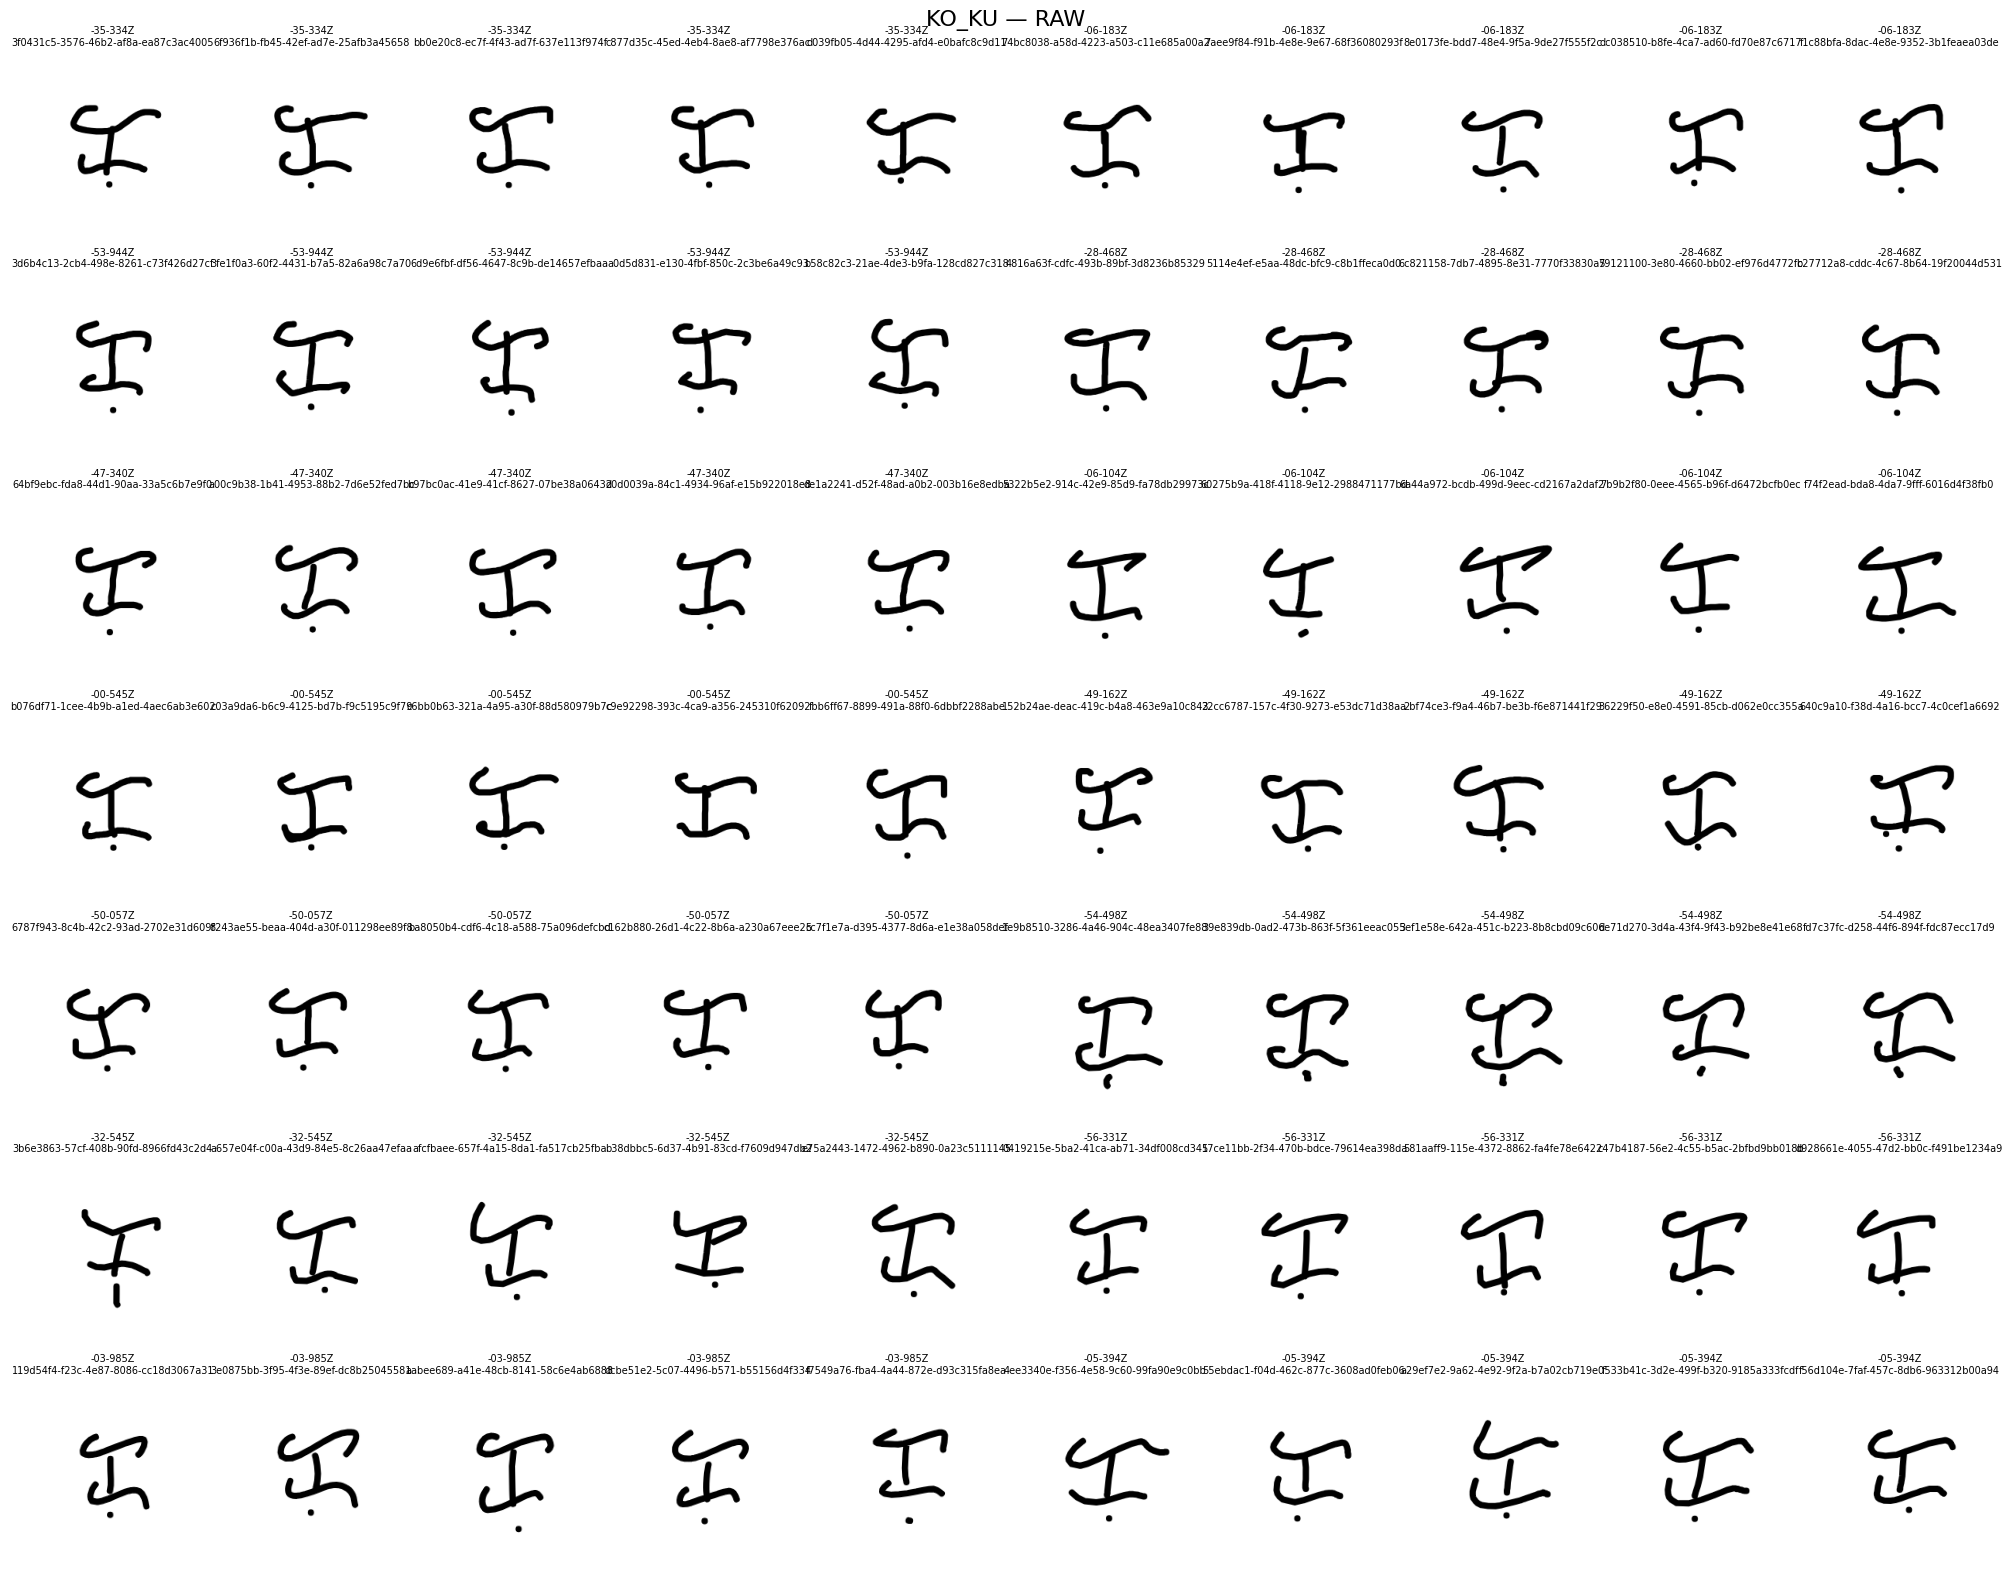

In [ ]:
show_all_class_samples(
    "k",
    preprocessed=False,
)

show_all_class_samples(
    "ka",
    preprocessed=False,
)

show_all_class_samples(
    "ke_ki",
    preprocessed=False,
)

show_all_class_samples(
    "ko_ku",
    preprocessed=False,
)

In [ ]:
KA_FAMILY = [
    "ka",
    "ke_ki",
    "ko_ku",
]

print("KA FAMILY INDICES")

for label in KA_FAMILY:
    print(
        f"{label:10s} -> {label_to_id[label]}"
    )

KA FAMILY INDICES
ka         -> 19
ke_ki      -> 20
ko_ku      -> 21


In [ ]:
# ============================================================
# FAMILY VISUAL COMPARISON
# Define this BEFORE calling show_family_samples(...)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def show_family_samples(
    family_labels,
    samples_per_class=10,
    seed=42,
    preprocessed=True,
):
    fig, axes = plt.subplots(
        len(family_labels),
        samples_per_class,
        figsize=(
            samples_per_class * 2,
            len(family_labels) * 2.4,
        ),
        squeeze=False,
    )

    for row_index, label in enumerate(family_labels):

        subset = df[
            df["label"].astype(str) == label
        ].copy()

        if len(subset) == 0:
            print(f"WARNING: No samples found for class: {label}")
            continue

        subset = subset.sample(
            n=min(samples_per_class, len(subset)),
            random_state=seed,
        ).reset_index(drop=True)

        for col_index in range(samples_per_class):

            ax = axes[row_index, col_index]
            ax.axis("off")

            if col_index >= len(subset):
                continue

            record = subset.iloc[col_index]

            if preprocessed:
                image = load_image_array(
                    record["image_path"]
                )[..., 0]

                ax.imshow(
                    image,
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

            else:
                image = Image.open(
                    record["image_path"]
                ).convert("RGBA")

                background = Image.new(
                    "RGBA",
                    image.size,
                    (255, 255, 255, 255),
                )

                background.alpha_composite(image)

                ax.imshow(
                    background.convert("L"),
                    cmap="gray",
                )

            if col_index == 0:
                ax.set_ylabel(
                    label.upper(),
                    fontsize=12,
                    fontweight="bold",
                )

            ax.set_title(
                str(record["source_export"])[-8:],
                fontsize=7,
            )

    mode = (
        "PREPROCESSED"
        if preprocessed
        else "RAW"
    )

    fig.suptitle(
        f"{' / '.join(x.upper() for x in family_labels)} — {mode}",
        fontsize=16,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

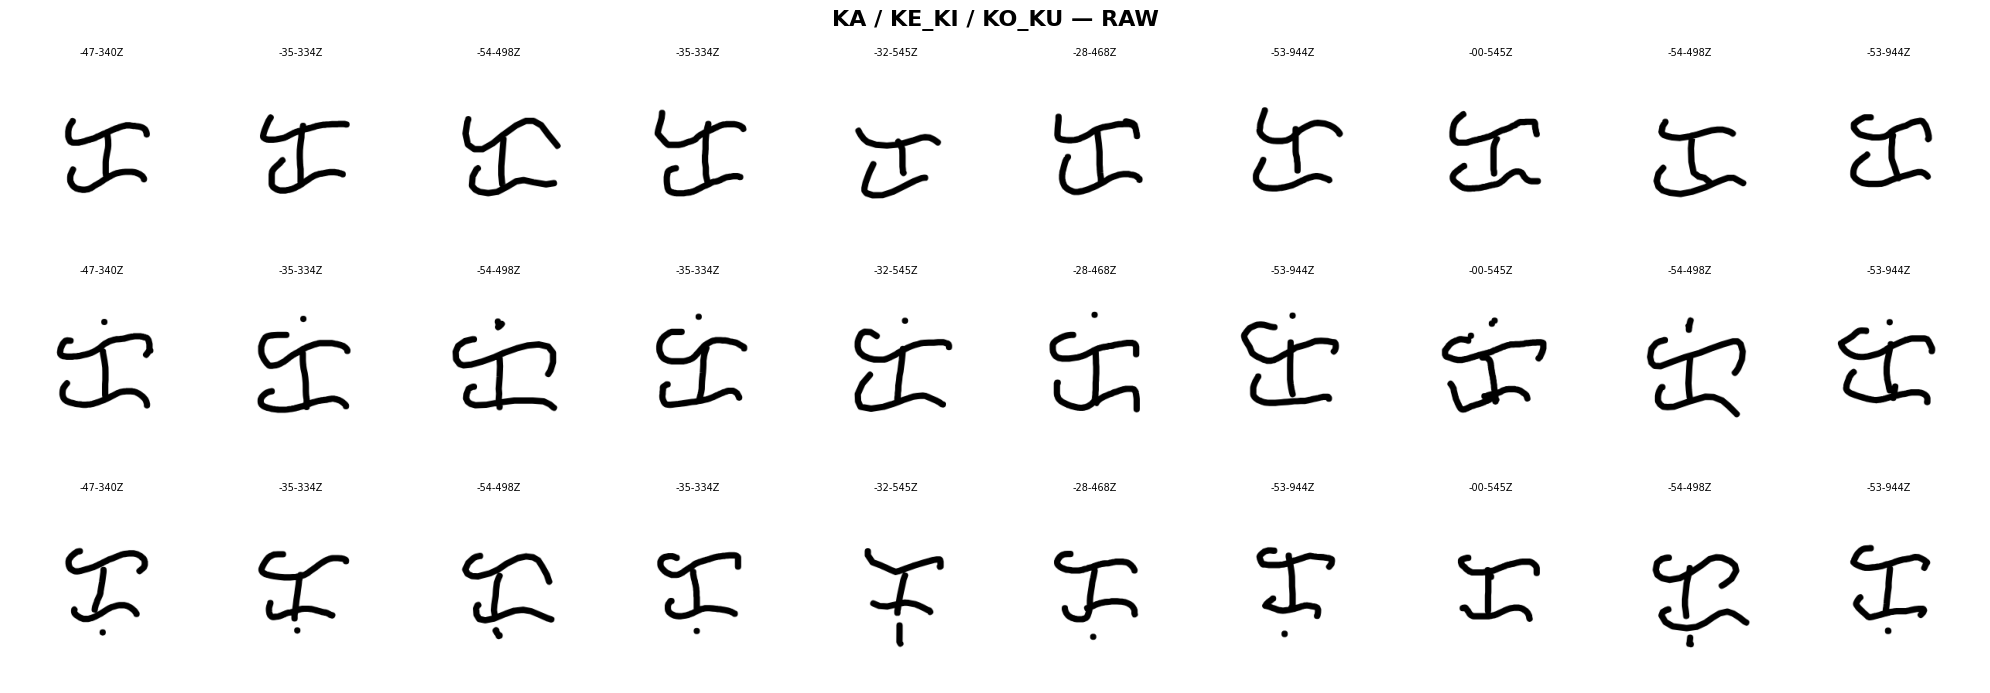

In [ ]:
show_family_samples(
    ["ka", "ke_ki", "ko_ku"],
    samples_per_class=10,
    preprocessed=False,
)

/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(
/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(
/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


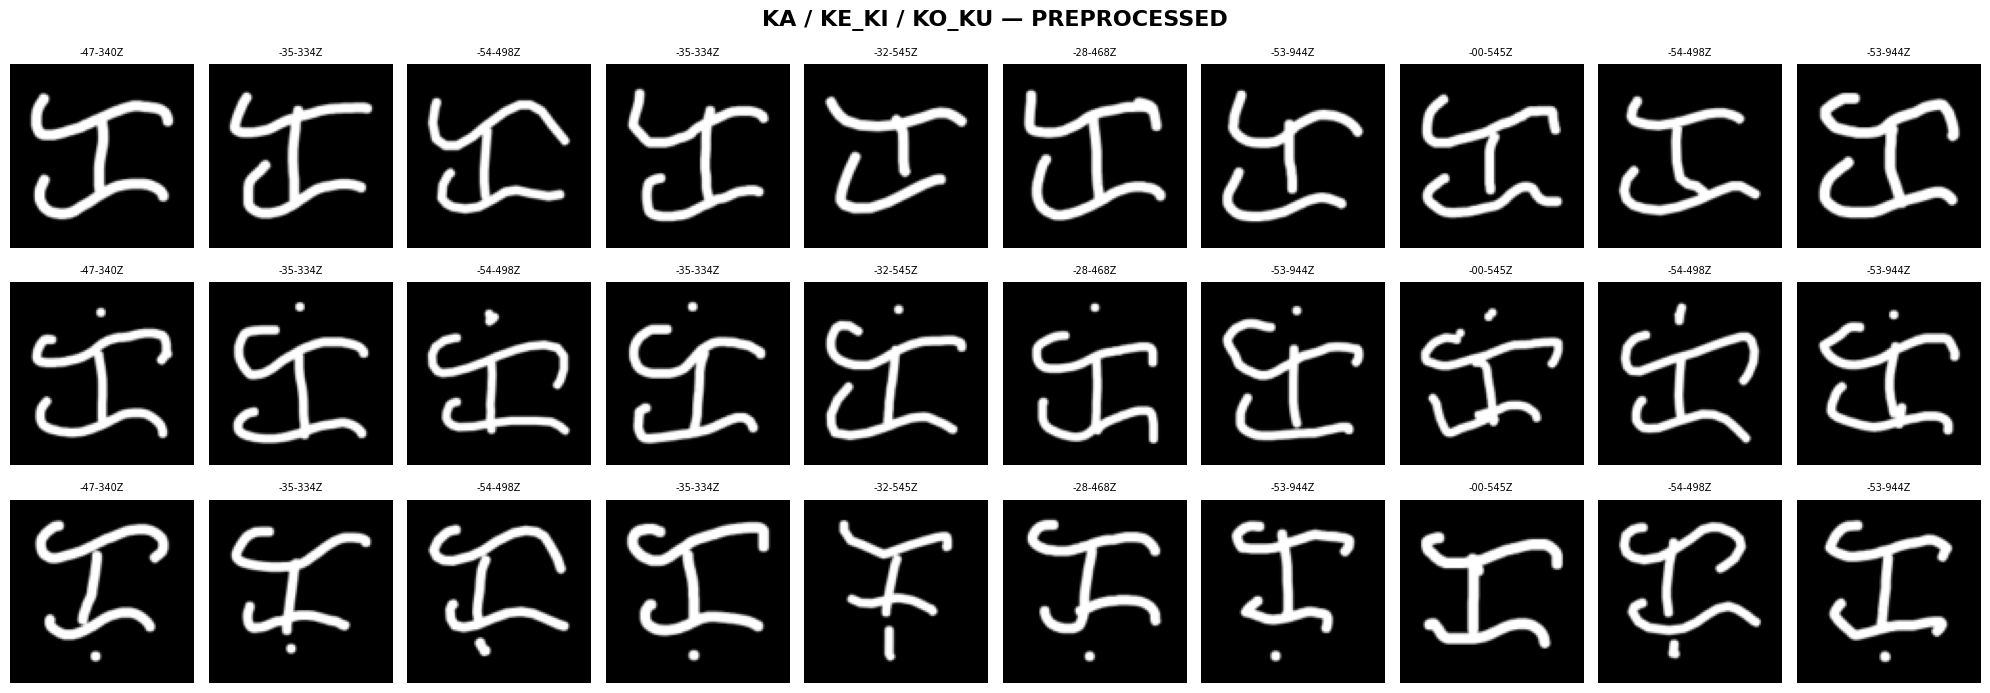

In [ ]:
show_family_samples(
    ["ka", "ke_ki", "ko_ku"],
    samples_per_class=10,
    preprocessed=True,
)

In [ ]:
# ============================================================
# TEST WHETHER FAINT GUIDE PIXELS ARE CONFUSING THE MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


def test_guide_removal(
    processed_image,
    model_to_use=None,
    thresholds=(0.05, 0.10, 0.15, 0.20, 0.25, 0.30),
    top_k=3,
):
    """
    Diagnostic only.

    Removes low-intensity pixels from an already preprocessed
    grayscale image to test whether faint guide/reference pixels
    are affecting classification.

    DO NOT use this as production preprocessing yet.
    """

    if model_to_use is None:
        if "best_model" in globals():
            model_to_use = best_model
        elif "model" in globals():
            model_to_use = model
        else:
            raise NameError("No model available.")

    # Accept HxWx1 or HxW
    base = np.asarray(processed_image, dtype=np.float32)

    if base.ndim == 3:
        base_2d = base[..., 0]
    else:
        base_2d = base

    results = []

    fig, axes = plt.subplots(
        1,
        len(thresholds) + 1,
        figsize=(3 * (len(thresholds) + 1), 3),
    )

    # Original
    axes[0].imshow(
        base_2d,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[0].set_title("Original")
    axes[0].axis("off")

    versions = [("original", base_2d)]

    for threshold in thresholds:
        cleaned = base_2d.copy()

        # Remove faint pixels
        cleaned[
            cleaned < threshold
        ] = 0.0

        versions.append(
            (f">= {threshold:.2f}", cleaned)
        )

    for plot_index, (
        name,
        image_2d,
    ) in enumerate(versions):

        x = image_2d[
            None,
            ...,
            None,
        ].astype(np.float32)

        probs = model_to_use.predict(
            x,
            verbose=0,
        )[0]

        top_ids = np.argsort(
            probs
        )[::-1][:top_k]

        top1_id = int(top_ids[0])

        results.append({
            "version": name,
            "top1": id_to_label[top1_id],
            "confidence": float(
                probs[top1_id]
            ),
            "P(KA)": float(
                probs[label_to_id["ka"]]
            ),
            "P(KE/KI)": float(
                probs[label_to_id["ke_ki"]]
            ),
            "P(KO/KU)": float(
                probs[label_to_id["ko_ku"]]
            ),
        })

        if plot_index > 0:
            axes[plot_index].imshow(
                image_2d,
                cmap="gray",
                vmin=0,
                vmax=1,
            )

            axes[plot_index].set_title(
                f"{name}\n"
                f"{id_to_label[top1_id].upper()} "
                f"{probs[top1_id]:.1%}"
            )

            axes[plot_index].axis("off")

    plt.tight_layout()
    plt.show()

    result_df = pd.DataFrame(results)

    display(
        result_df.style.format({
            "confidence": "{:.2%}",
            "P(KA)": "{:.2%}",
            "P(KE/KI)": "{:.2%}",
            "P(KO/KU)": "{:.2%}",
        })
    )

    return result_df

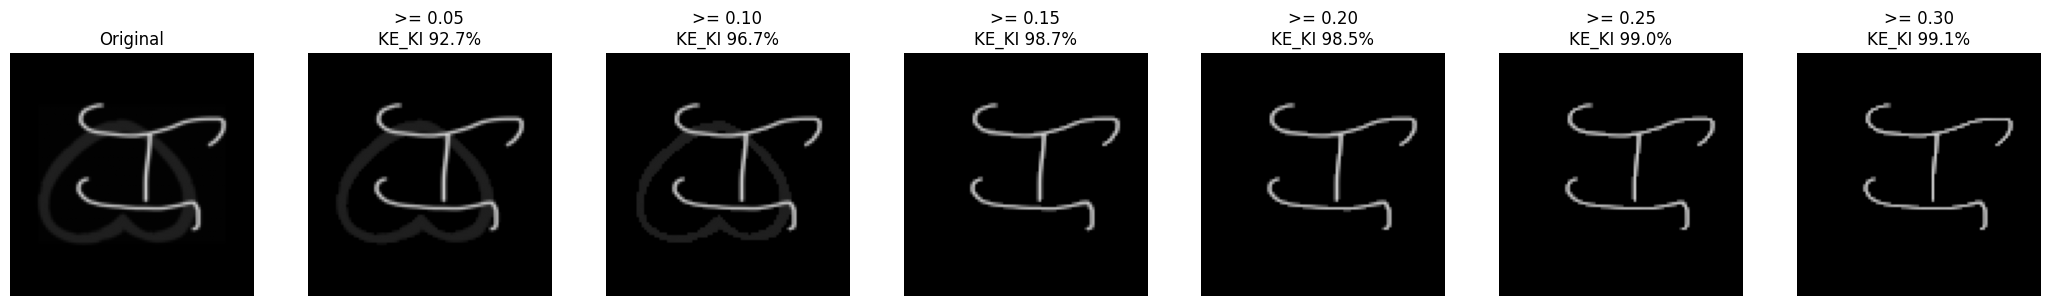

,version,top1,confidence,P(KA),P(KE/KI),P(KO/KU)
0,original,ke_ki,92.43%,4.22%,92.43%,1.07%
1,>= 0.05,ke_ki,92.74%,4.67%,92.74%,0.97%
2,>= 0.10,ke_ki,96.68%,1.75%,96.68%,0.69%
3,>= 0.15,ke_ki,98.71%,0.03%,98.71%,1.21%
4,>= 0.20,ke_ki,98.50%,0.04%,98.50%,1.40%
5,>= 0.25,ke_ki,99.04%,0.02%,99.04%,0.89%
6,>= 0.30,ke_ki,99.08%,0.02%,99.08%,0.84%


In [ ]:
guide_test = test_guide_removal(
    processed_live
)

In [ ]:
# ============================================================
# COUNTERFACTUAL TEST:
# Remove small disconnected components (such as kudlit)
# from KE/KI images and see whether the model still
# predicts KE/KI.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage


def remove_small_components(
    image,
    threshold=0.20,
    keep_largest=True,
):
    """
    Diagnostic only.

    image:
        HxWx1 or HxW float image in [0, 1]

    This identifies connected ink components and,
    when keep_largest=True, preserves only the
    largest connected component.

    For many KE/KI samples, this should remove the
    detached upper kudlit while preserving the main glyph.
    """

    img = np.asarray(
        image,
        dtype=np.float32
    )

    if img.ndim == 3:
        img = img[..., 0]

    binary = (
        img >= threshold
    )

    labels, num_components = ndimage.label(
        binary
    )

    if num_components == 0:
        return img.copy(), 0

    component_sizes = ndimage.sum(
        binary,
        labels,
        index=np.arange(
            1,
            num_components + 1
        )
    )

    if keep_largest:
        largest_label = (
            int(
                np.argmax(
                    component_sizes
                )
            )
            + 1
        )

        keep_mask = (
            labels == largest_label
        )

        cleaned = np.where(
            keep_mask,
            img,
            0.0
        )

    else:
        cleaned = img.copy()

    return (
        cleaned.astype(np.float32),
        num_components,
    )


def predict_single_processed(
    processed_image,
    model_to_use=None,
):
    if model_to_use is None:
        if "best_model" in globals():
            model_to_use = best_model
        elif "model" in globals():
            model_to_use = model
        else:
            raise NameError(
                "No model found."
            )

    img = np.asarray(
        processed_image,
        dtype=np.float32
    )

    if img.ndim == 2:
        img = img[..., None]

    x = img[None, ...]

    probs = model_to_use.predict(
        x,
        verbose=0
    )[0]

    pred_id = int(
        np.argmax(probs)
    )

    return {
        "pred_id": pred_id,
        "predicted": id_to_label[pred_id],
        "confidence": float(probs[pred_id]),
        "P(KA)": float(
            probs[label_to_id["ka"]]
        ),
        "P(KE/KI)": float(
            probs[label_to_id["ke_ki"]]
        ),
        "P(KO/KU)": float(
            probs[label_to_id["ko_ku"]]
        ),
        "probabilities": probs,
    }

In [ ]:
# ============================================================
# TEST ALL KE/KI TEST SAMPLES BEFORE/AFTER KUDLIT REMOVAL
# ============================================================

ke_ki_id = label_to_id["ke_ki"]

ke_ki_indices = np.where(
    y_test == ke_ki_id
)[0]

counterfactual_rows = []

for idx in ke_ki_indices:

    original = Ximg_test[
        idx,
        ...,
        0
    ]

    cleaned, components = (
        remove_small_components(
            original,
            threshold=0.20
        )
    )

    original_result = (
        predict_single_processed(
            original
        )
    )

    cleaned_result = (
        predict_single_processed(
            cleaned
        )
    )

    counterfactual_rows.append({
        "test_index": int(idx),

        "components":
            components,

        "original_pred":
            original_result[
                "predicted"
            ],

        "original_conf":
            original_result[
                "confidence"
            ],

        "without_kudlit_pred":
            cleaned_result[
                "predicted"
            ],

        "without_kudlit_conf":
            cleaned_result[
                "confidence"
            ],

        "without_kudlit_P(KA)":
            cleaned_result[
                "P(KA)"
            ],

        "without_kudlit_P(KE/KI)":
            cleaned_result[
                "P(KE/KI)"
            ],
    })


counterfactual_df = pd.DataFrame(
    counterfactual_rows
)

display(
    counterfactual_df.style.format({
        "original_conf": "{:.2%}",
        "without_kudlit_conf": "{:.2%}",
        "without_kudlit_P(KA)": "{:.2%}",
        "without_kudlit_P(KE/KI)": "{:.2%}",
    })
)

,test_index,components,original_pred,original_conf,without_kudlit_pred,without_kudlit_conf,without_kudlit_P(KA),without_kudlit_P(KE/KI)
0,100,3,de_di,78.56%,ha,85.86%,0.00%,0.00%
1,101,2,ke_ki,99.73%,ke_ki,85.45%,13.14%,85.45%
2,102,2,ke_ki,99.83%,ka,58.99%,58.99%,40.82%
3,103,2,ke_ki,88.10%,ke_ki,54.46%,0.11%,54.46%
4,104,2,ke_ki,99.23%,ke_ki,96.56%,2.10%,96.56%
5,415,2,ke_ki,99.96%,ke_ki,65.77%,34.06%,65.77%
6,416,2,ke_ki,98.57%,ke_ki,98.19%,0.13%,98.19%
7,417,2,ke_ki,99.98%,ke_ki,99.14%,0.70%,99.14%
8,418,2,ke_ki,99.84%,ke_ki,97.50%,1.07%,97.50%
9,419,2,ke_ki,98.18%,ke_ki,91.53%,2.17%,91.53%


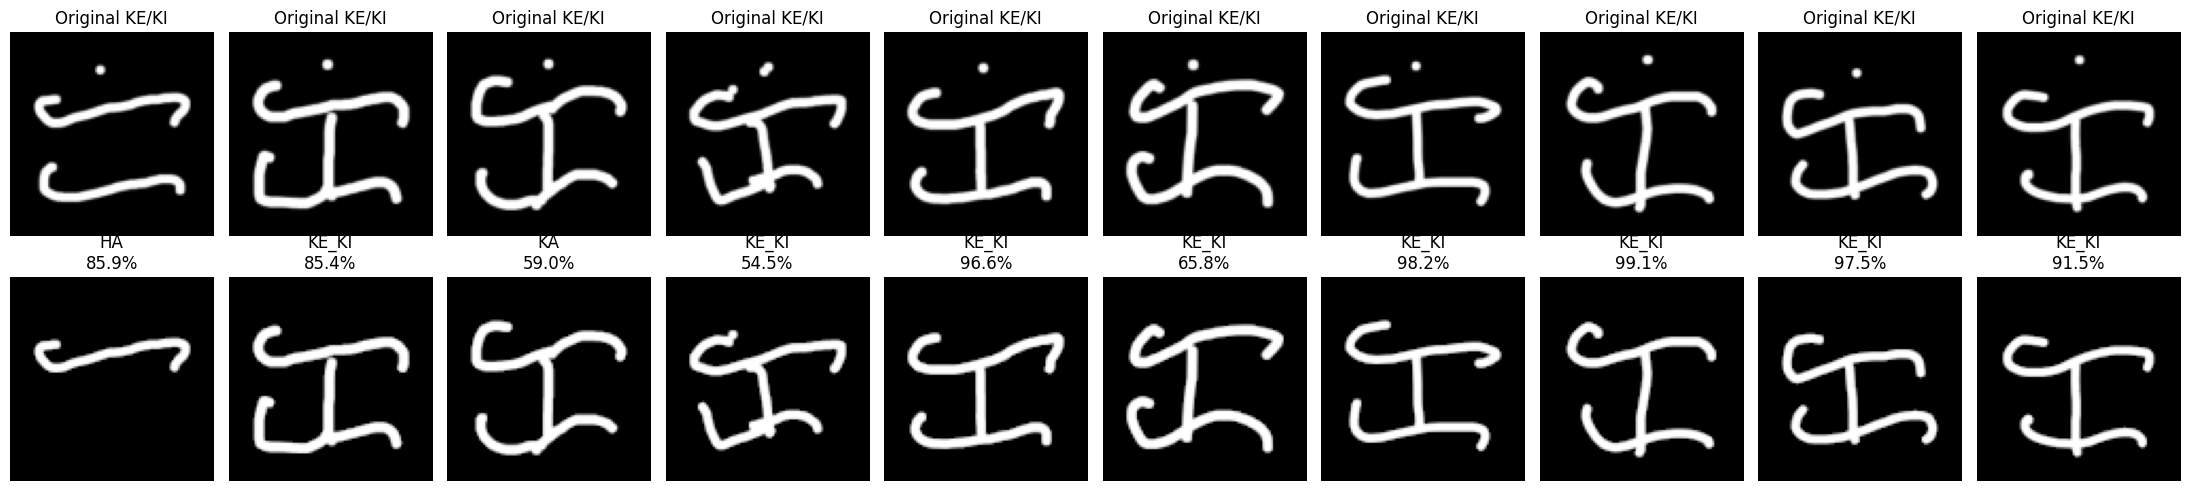

In [ ]:
# ============================================================
# VISUALIZE ORIGINAL KE/KI VS KUDLIT-REMOVED VERSION
# ============================================================

max_show = min(
    10,
    len(ke_ki_indices)
)

fig, axes = plt.subplots(
    2,
    max_show,
    figsize=(
        max_show * 2.2,
        5
    ),
    squeeze=False,
)

for j, idx in enumerate(
    ke_ki_indices[:max_show]
):

    original = Ximg_test[
        idx,
        ...,
        0
    ]

    cleaned, _ = (
        remove_small_components(
            original,
            threshold=0.20
        )
    )

    cleaned_result = (
        predict_single_processed(
            cleaned
        )
    )

    axes[0, j].imshow(
        original,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, j].set_title(
        "Original KE/KI"
    )

    axes[0, j].axis("off")


    axes[1, j].imshow(
        cleaned,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, j].set_title(
        f"{cleaned_result['predicted'].upper()}\n"
        f"{cleaned_result['confidence']:.1%}"
    )

    axes[1, j].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STRONGER COUNTERFACTUAL TEST
# Remove upper kudlit BEFORE BAYA preprocessing,
# then run the normal load_image_array() again.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage
from pathlib import Path
import tempfile


def remove_upper_kudlit_from_raw(
    image_path,
    ink_threshold=0.08,
    max_component_ratio=0.20,
):
    """
    Diagnostic only.

    Removes small detached ink components located ABOVE
    the main Baybayin glyph BEFORE normal BAYA preprocessing.

    This is intended to remove the detached upper kudlit
    from KE/KI examples.

    Returns:
        cleaned PIL image
        diagnostic dictionary
    """

    image_path = Path(image_path)

    # Load and composite onto white
    rgba = Image.open(
        image_path
    ).convert("RGBA")

    white = Image.new(
        "RGBA",
        rgba.size,
        (255, 255, 255, 255),
    )

    white.alpha_composite(rgba)

    rgb = white.convert("RGB")

    gray = np.asarray(
        rgb.convert("L"),
        dtype=np.float32,
    ) / 255.0

    # Same basic ink convention:
    # white background -> 0 ink
    # dark stroke      -> high ink
    ink = 1.0 - gray

    binary = (
        ink > ink_threshold
    )

    labels, num_components = (
        ndimage.label(binary)
    )

    if num_components < 2:
        return rgb, {
            "components": num_components,
            "removed_components": 0,
            "removed_pixels": 0,
        }

    objects = ndimage.find_objects(
        labels
    )

    stats = []

    for component_id in range(
        1,
        num_components + 1
    ):
        mask = (
            labels == component_id
        )

        area = int(mask.sum())

        if area == 0:
            continue

        ys, xs = np.where(mask)

        stats.append({
            "id": component_id,
            "area": area,
            "y_min": int(ys.min()),
            "y_max": int(ys.max()),
            "x_min": int(xs.min()),
            "x_max": int(xs.max()),
            "cy": float(ys.mean()),
            "cx": float(xs.mean()),
        })

    if not stats:
        return rgb, {
            "components": 0,
            "removed_components": 0,
            "removed_pixels": 0,
        }

    # Largest component = main glyph
    main = max(
        stats,
        key=lambda x: x["area"]
    )

    main_area = main["area"]

    candidate_ids = []

    for component in stats:

        if component["id"] == main["id"]:
            continue

        area_ratio = (
            component["area"]
            / max(main_area, 1)
        )

        # Strict criterion:
        # component must be relatively small
        # AND physically above the main component
        is_small = (
            area_ratio
            <= max_component_ratio
        )

        is_above = (
            component["cy"]
            < main["y_min"]
        )

        if is_small and is_above:
            candidate_ids.append(
                component["id"]
            )

    cleaned_array = np.asarray(
        rgb
    ).copy()

    removed_pixels = 0

    for component_id in candidate_ids:

        mask = (
            labels == component_id
        )

        removed_pixels += int(
            mask.sum()
        )

        # Paint removed kudlit white
        cleaned_array[
            mask
        ] = [255, 255, 255]

    cleaned_image = Image.fromarray(
        cleaned_array.astype(
            np.uint8
        )
    )

    diagnostics = {
        "components":
            num_components,

        "removed_components":
            len(candidate_ids),

        "removed_pixels":
            removed_pixels,

        "main_area":
            main_area,

        "candidate_ids":
            candidate_ids,
    }

    return (
        cleaned_image,
        diagnostics,
    )

In [ ]:
# ============================================================
# RUN RAW-KUDLIT-REMOVED IMAGE THROUGH REAL PREPROCESSING
# ============================================================

def preprocess_cleaned_raw(
    cleaned_pil_image,
):
    """
    Saves the diagnostic image temporarily and passes it
    through the notebook's existing load_image_array()
    so bbox/crop/padding/resize are recomputed.
    """

    with tempfile.NamedTemporaryFile(
        suffix=".png",
        delete=False,
    ) as temp_file:

        temp_path = Path(
            temp_file.name
        )

    cleaned_pil_image.save(
        temp_path
    )

    processed = load_image_array(
        str(temp_path)
    )

    try:
        temp_path.unlink()
    except Exception:
        pass

    return processed

In [ ]:
# ============================================================
# PREDICT ONE PREPROCESSED IMAGE
# ============================================================

def predict_processed_image(
    processed,
    model_to_use=None,
):
    if model_to_use is None:

        if "best_model" in globals():
            model_to_use = best_model

        elif "model" in globals():
            model_to_use = model

        else:
            raise NameError(
                "No model available."
            )

    image = np.asarray(
        processed,
        dtype=np.float32,
    )

    if image.ndim == 2:
        image = image[
            ...,
            None
        ]

    x = image[
        None,
        ...
    ]

    probs = model_to_use.predict(
        x,
        verbose=0,
    )[0]

    pred_id = int(
        np.argmax(probs)
    )

    return {
        "predicted":
            id_to_label[pred_id],

        "confidence":
            float(probs[pred_id]),

        "P(KA)":
            float(
                probs[
                    label_to_id["ka"]
                ]
            ),

        "P(KE/KI)":
            float(
                probs[
                    label_to_id["ke_ki"]
                ]
            ),

        "P(KO/KU)":
            float(
                probs[
                    label_to_id["ko_ku"]
                ]
            ),
    }

In [ ]:
# ============================================================
# TRUE COUNTERFACTUAL:
# KE/KI original vs kudlit removed BEFORE preprocessing
# ============================================================

ke_ki_id = label_to_id[
    "ke_ki"
]

ke_ki_indices = np.where(
    y_test == ke_ki_id
)[0]

rows = []

cleaned_examples = []


for idx in ke_ki_indices:

    record = test_df.iloc[
        int(idx)
    ]

    image_path = record[
        "image_path"
    ]

    # Original model-ready image
    original_processed = (
        load_image_array(
            image_path
        )
    )

    original_result = (
        predict_processed_image(
            original_processed
        )
    )


    # Remove upper kudlit BEFORE preprocessing
    cleaned_raw, diagnostics = (
        remove_upper_kudlit_from_raw(
            image_path
        )
    )

    # Re-run normal BAYA preprocessing
    cleaned_processed = (
        preprocess_cleaned_raw(
            cleaned_raw
        )
    )

    cleaned_result = (
        predict_processed_image(
            cleaned_processed
        )
    )


    rows.append({
        "test_index":
            int(idx),

        "removed_components":
            diagnostics[
                "removed_components"
            ],

        "original_pred":
            original_result[
                "predicted"
            ],

        "original_conf":
            original_result[
                "confidence"
            ],

        "without_kudlit_pred":
            cleaned_result[
                "predicted"
            ],

        "without_kudlit_conf":
            cleaned_result[
                "confidence"
            ],

        "without_kudlit_P(KA)":
            cleaned_result[
                "P(KA)"
            ],

        "without_kudlit_P(KE/KI)":
            cleaned_result[
                "P(KE/KI)"
            ],

        "without_kudlit_P(KO/KU)":
            cleaned_result[
                "P(KO/KU)"
            ],
    })


    cleaned_examples.append({
        "index":
            int(idx),

        "original":
            original_processed[
                ...,
                0
            ],

        "cleaned":
            cleaned_processed[
                ...,
                0
            ],

        "prediction":
            cleaned_result[
                "predicted"
            ],

        "confidence":
            cleaned_result[
                "confidence"
            ],
    })


true_counterfactual_df = (
    pd.DataFrame(rows)
)


display(
    true_counterfactual_df.style.format({
        "original_conf":
            "{:.2%}",

        "without_kudlit_conf":
            "{:.2%}",

        "without_kudlit_P(KA)":
            "{:.2%}",

        "without_kudlit_P(KE/KI)":
            "{:.2%}",

        "without_kudlit_P(KO/KU)":
            "{:.2%}",
    })
)

/tmp/ipykernel_1561/1117675343.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


,test_index,removed_components,original_pred,original_conf,without_kudlit_pred,without_kudlit_conf,without_kudlit_P(KA),without_kudlit_P(KE/KI),without_kudlit_P(KO/KU)
0,100,1,de_di,78.56%,de_di,64.42%,0.01%,0.53%,0.01%
1,101,1,ke_ki,99.73%,ke_ki,91.53%,7.34%,91.53%,0.87%
2,102,1,ke_ki,99.83%,ka,54.87%,54.87%,44.67%,0.29%
3,103,1,ke_ki,88.10%,ko_ku,70.13%,0.04%,27.53%,70.13%
4,104,1,ke_ki,99.23%,ke_ki,89.63%,1.40%,89.63%,7.97%
5,415,1,ke_ki,99.96%,ka,76.96%,76.96%,22.81%,0.13%
6,416,1,ke_ki,98.57%,ke_ki,97.84%,0.08%,97.84%,1.99%
7,417,1,ke_ki,99.98%,ke_ki,73.27%,26.22%,73.27%,0.40%
8,418,1,ke_ki,99.84%,ke_ki,95.92%,1.15%,95.92%,2.27%
9,419,1,ke_ki,98.18%,ke_ki,86.12%,5.24%,86.12%,5.84%


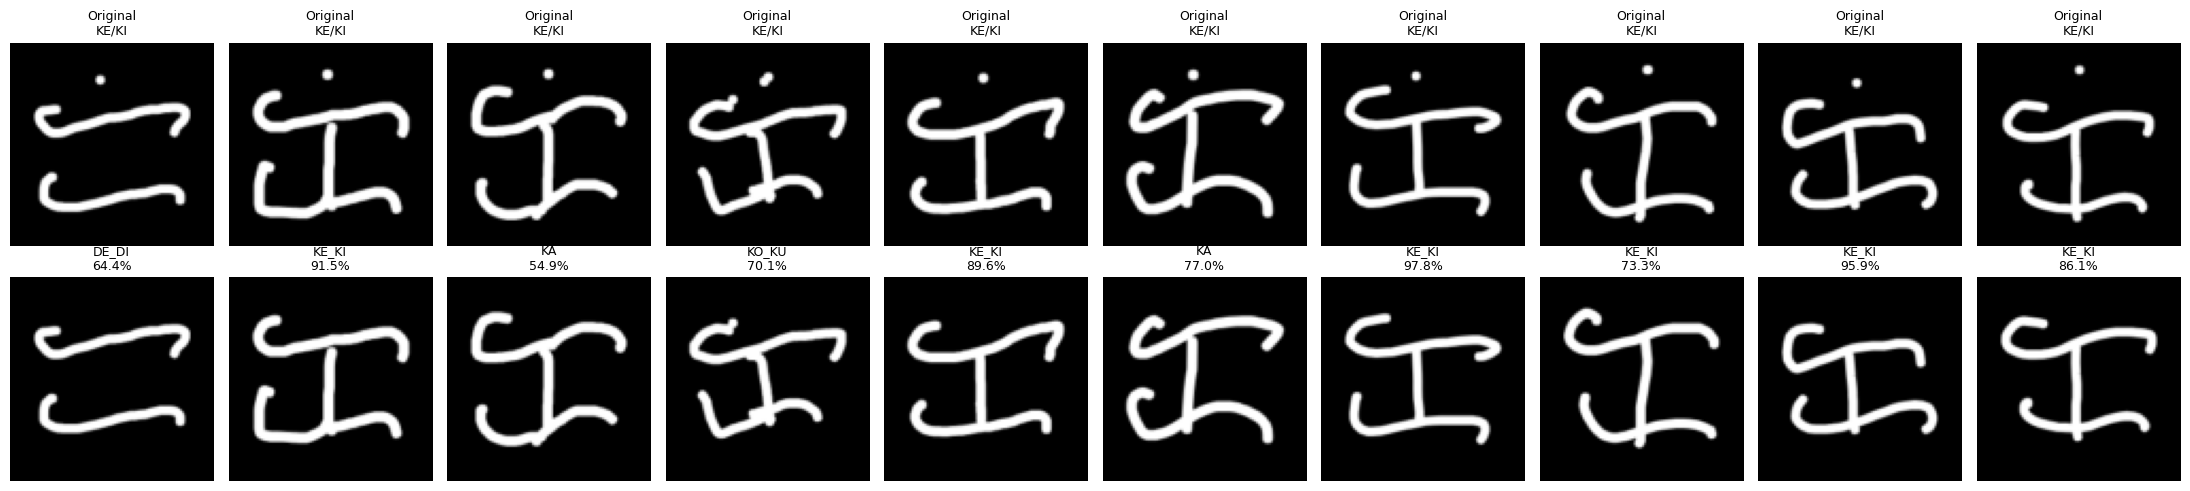

In [ ]:
# ============================================================
# VISUALIZE ORIGINAL VS TRUE REPROCESSED COUNTERFACTUAL
# ============================================================

max_show = min(
    10,
    len(cleaned_examples)
)

fig, axes = plt.subplots(
    2,
    max_show,
    figsize=(
        max_show * 2.2,
        5,
    ),
    squeeze=False,
)


for j in range(max_show):

    item = cleaned_examples[j]

    axes[0, j].imshow(
        item["original"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[0, j].set_title(
        "Original\nKE/KI",
        fontsize=9,
    )

    axes[0, j].axis("off")


    axes[1, j].imshow(
        item["cleaned"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[1, j].set_title(
        f"{item['prediction'].upper()}\n"
        f"{item['confidence']:.1%}",
        fontsize=9,
    )

    axes[1, j].axis("off")


plt.tight_layout()
plt.show()